# FDA Medical Warning Letters – Scraping & Text Analysis (גרסה מתוקנת)

המחברת אוספת מאתר ה-FDA מכתבי אזהרה בתחום התרופות, ומנתחת את הטקסט שלהם בכמה שיטות NLP כדי לגלות **על מה ה-FDA מתריע ואיך זה משתנה בין השנים**.

| סעיף | מה הוא עושה |
|---|---|
| 0 | הגדרות, ספריות, ההגדרה של "מכתב רפואי" |
| 1 | איסוף הטבלה של כל המכתבים (כולל תאריך ונושא רשמי) והורדת המכתבים |
| 2 | טעינה, תאריכים, חילוץ גוף המכתב |
| 3 | מספר מכתבים לפי שנה |
| 4 | מונחים דומיננטיים (TF-IDF) |
| 5 | חלוקה לנושאים עם K-Means (מספר הקבוצות נבחר לפי Silhouette) |
| 6 | חלוקה סמנטית עם Sentence-BERT על **כל** המכתב + עץ היררכי |
| 7 | מילות מפתח מבדלות לכל קבוצה, שמות אוטומטיים, מפת t-SNE ודנדרוגרמה |
| 8 | סיווג Zero-Shot עם DeBERTa, **בדיקת דיוק** מול הנושא הרשמי של ה-FDA, ומגמות באחוזים |
| 9 | שמירת התוצאות והורדה למחשב |
| 10 | מסקנות (למלא אחרי הריצה) |

### מה תוקן לעומת הגרסה הקודמת
| # | בעיה | התיקון |
|---|---|---|
| 1 | בגרף המגמות שני קווים באותו צבע, ושמות שלא תואמים לקטגוריות | צבע קבוע לכל קטגוריה, מקרא לפי השמות האמיתיים, גרף נוסף באחוזים |
| 2 | שמות הקבוצות נכתבו ידנית וסתרו זה את זה | השמות נוצרים אוטומטית מהמילים המבדלות; סעיפים 6 ו-7 משתמשים באותה חלוקה |
| 3 | Sentence-BERT קרא רק ~200 מילים ראשונות (הכותרת) | כל מכתב מחולק לקטעים, כל קטע מקודד, ומחשבים ממוצע |
| 4 | DeBERTa פיצל לפי `\n\n` שלא קיים, וסיווג רק את 1,000 התווים הראשונים | פיצול אמיתי לקטעים מגוף המכתב + בדיקת דיוק מול נושא ה-FDA |
| 5 | התאריכים נוחשו מהטקסט (חודש תמיד יוני, ברירת מחדל 2025) | תאריך הוצאת המכתב נלקח מטבלת ה-FDA עצמה |
| 6 | מגמות במספרים מוחלטים | גם אחוז מכלל המכתבים בכל שנה |
| 7 | סעיף 4: מכפילים שרירותיים, אותו מושג נספר כמה פעמים, מילות נושא נמחקו | בלי מכפילים, כל מושג פעם אחת, רשימה "חופשית" לצד הרשימה הקלינית |
| 8 | המספר 3 נבחר בלי הצדקה | בדיקת Silhouette ל-k=2..8 |
| 9 | c-TF-IDF הוציא מילים כלליות (including, address, https) | ציון מבדל: ממוצע בתוך הקבוצה פחות ממוצע מחוצה לה, עם רשימת עצירה מלאה |
| 10 | סינון "רפואי" לפי מילה בתוך שם המשרד, לא עקבי | כלל מפורש עם הכללה והחרגה, שנבדק מול כל 3,768 המכתבים, וטבלה מלאה של כל המשרדים לנספח |
| 12 | 3 מתוך 5 קטגוריות של DeBERTa כמעט ריקות | 4 קטגוריות שמבוססות על הנושאים הרשמיים של ה-FDA (כולל Compounding) + בדיקה ידנית של מדגם |
| 11 | הקבצים נמחקים כש-Colab מתנתק | אפשרות לשמור ב-Google Drive והורדה אוטומטית של קובץ התוצאות |

> **שים לב:** אחרי התיקונים צריך להריץ את כל המחברת מחדש. המספרים והגרפים ישתנו, ולכן גם המסקנות בסעיף 10 נכתבות רק אחרי הריצה.

## 0. Setup

### 0.1 התקנת ספריות
ב-Colab רובן כבר מותקנות. מספיק להריץ פעם אחת.

In [107]:
!pip3 install -q scipy sentence-transformers transformers statsmodels bertopic prophet streamlit plotly

### 0.2 Imports
כל הספריות במקום אחד. מודלי השפה (`torch`, `sentence_transformers`, `transformers`) נטענים כאן, אבל המודלים עצמם יורדו רק בסעיפים 6 ו-8.

In [108]:
import json
import logging
import re
import time
import warnings
from pathlib import Path
from typing import Iterable
from urllib.parse import urljoin

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.feature_extraction import text as sk_text
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, classification_report, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from tqdm.auto import tqdm
from statsmodels.nonparametric.smoothers_lowess import lowess
import plotly.io as pio

import torch
from sentence_transformers import SentenceTransformer
from transformers import pipeline
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from prophet import Prophet

HORIZONTAL_YLABEL = dict(rotation=0, ha="right", va="center")
pio.renderers.default = "plotly_mimetype+notebook_connected"
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.WARNING)

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

### 0.2.1 גרסאות הספריות
התא מדפיס את גרסת Python ואת גרסאות הספריות שמשמשות לניתוח, כדי שאפשר יהיה לשחזר את התוצאות על מחשב אחר.

In [109]:
import sys
import scipy
import sklearn
import statsmodels
import sentence_transformers
import transformers
import bertopic
import prophet

versions = {
    "python": sys.version.split()[0],
    "scikit-learn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "sentence-transformers": sentence_transformers.__version__,
    "transformers": transformers.__version__,
    "torch": torch.__version__,
    "bertopic": bertopic.__version__,
    "prophet": prophet.__version__,
    "statsmodels": statsmodels.__version__,
}
for name, ver in versions.items():
    print(f"{name:24s} {ver}")


python                   3.13.16
scikit-learn             1.6.1
numpy                    2.1.3
pandas                   2.2.3
scipy                    1.16.3
sentence-transformers    5.7.0
transformers             5.20.2
torch                    2.11.0+cu130
bertopic                 0.17.4
prophet                  1.5.0
statsmodels              0.15.0


### 0.3 הגדרות ריצה ושמירת קבצים
* `SAVE_TO_DRIVE = True` שומר את כל הקבצים ב-Google Drive, כך שהם לא נמחקים כש-Colab מתנתק. מומלץ.
* `PAGE_SIZE`, `MAX_LETTERS`, `DELAY_SECONDS` – כמו קודם.
* `YEAR_MIN`, `YEAR_MAX` – טווח השנים לניתוח.

In [110]:
SAVE_TO_DRIVE = False          # change to True in Colab to keep files in Google Drive
DATA_DIR = Path("data")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/FDA_project')
DATA_DIR.mkdir(parents=True, exist_ok=True)

META_OUT     = DATA_DIR / "all_warning_letters_index.csv"   # every letter in the FDA table
OFFICES_OUT  = DATA_DIR / "issuing_offices.csv"             # office list + included / excluded
URLS_OUT     = DATA_DIR / "medical_warning_letter_urls.txt"
JSONL_OUT    = DATA_DIR / "medical_warning_letters.jsonl"
RESULTS_OUT  = DATA_DIR / "fda_letters_results.csv"

PAGE_SIZE     = 100
MAX_LETTERS   = 0       # 0 = all
DELAY_SECONDS = 0.4
YEAR_MIN, YEAR_MAX = 2021, 2026
RANDOM_STATE  = 42
print(f"📁 Files will be saved in: {DATA_DIR.resolve()}")

📁 Files will be saved in: /content/data


### 0.4 ההגדרה של "מכתב רפואי"
אין ב-FDA שדה רשמי שאומר "המכתב הזה רפואי". מה שכן יש הוא **המשרד המנפיק**, שמראה איזה מרכז של ה-FDA אחראי על המוצר. לכן ההגדרה בפרויקט היא:

> **מכתב רפואי = מכתב שהונפק על ידי משרד שאחראי על תרופות (CDER, Pharmaceutical Quality, Drug) או על מוצרים ביולוגיים (CBER, Biological Products).** משרדים של מכשור, קרינה, מזון, טבק, וטרינריה וקוסמטיקה מוחרגים במפורש.

**איך ההגדרה נבדקה:** הרצנו את הכלל על כל 3,768 המכתבים בטבלה של ה-FDA ועברנו על כל שמות המשרדים:
* כל וריאציות הכתיב של CDER, CBER, משרדי ה-Pharmaceutical Quality Operations ומשרדי ה-Biological Products Operations נכללות.
* `Office of Manufacturing Quality` הוא משרד של CDER בלי המילה Drug בשם, ולכן הוא נוסף ידנית ב-`MANUAL_INCLUDE`.
* `Office of Inspections and Investigations` מוחרג: כל המכתבים שלו עוסקים במזון (FSVP, Seafood HACCP).
* משרדי ה-Imports מוחרגים, כי הם מטפלים בכל סוגי המוצרים.

אפשרויות:
* הבדיקה היא לפי **מילה שלמה** (`\b`), כדי ש-`medical` לא יתפוס בטעות משרד מכשור.
* `INCLUDE_DEVICES = True` מוסיף גם את מכתבי המכשור הרפואי, אם המנחה רוצה הגדרה רחבה.
* `MANUAL_INCLUDE` / `MANUAL_EXCLUDE` מאפשרים להוסיף או להוציא משרד ספציפי אחרי שבודקים את הטבלה בסעיף 1.5.
* הטבלה המלאה של כל המשרדים (כלול / לא כלול) נשמרת ל-`issuing_offices.csv` לנספח של העבודה.

In [111]:
INCLUDE_DEVICES = False
INCLUDE_RE = re.compile(r'\b(drugs?|cder|pharmaceuticals?|pharmacy|biolog\w*|cber)\b', re.I)
EXCLUDE_RE = re.compile(r'device|radiolog|cdrh|food|nutrition|tobacco|veterinar|cosmetic', re.I)
DEVICE_RE  = re.compile(r'device|cdrh', re.I)

MANUAL_INCLUDE = {"Office of Manufacturing Quality"}   # exact office names to force in
MANUAL_EXCLUDE = set()   # exact office names to force out

def is_medical_office(name) -> bool:
    name = name if isinstance(name, str) else ""
    if name in MANUAL_EXCLUDE:
        return False
    if name in MANUAL_INCLUDE:
        return True
    if INCLUDE_DEVICES and DEVICE_RE.search(name):
        return True
    return bool(INCLUDE_RE.search(name)) and not EXCLUDE_RE.search(name)

## 1. Extract Data From the FDA Website

### 1.1 API constants
כמו קודם: כתובת האתר, כתובת ה-API שממנו טבלת המכתבים נטענת, והביטוי שמזהה קישור למכתב.

In [112]:
BASE_URL = "https://www.fda.gov"
LIST_PATH = (
    "/inspections-compliance-enforcement-and-criminal-investigations/"
    "compliance-actions-and-activities/warning-letters"
)
DT_URL = f"{BASE_URL}/datatables/views/ajax"

VIEW_PARAMS = {
    "_drupal_ajax": 1,
    "_wrapper_format": "drupal_ajax",
    "pager_element": 0,
    "view_args": "",
    "view_base_path": (
        "inspections-compliance-enforcement-and-criminal-investigations/"
        "compliance-actions-and-activities/warning-letters/datatables-data"
    ),
    "view_display_id": "warning_letter_solr_block",
    "view_dom_id": "c6eefb6fe061b4b0d0aac545115623ca9dc74414ec52ab322e1eafc17ee420bd",
    "view_name": "warning_letter_solr_index",
    "view_path": LIST_PATH,
    "total_items": 3474,
}

LETTER_PATH_RE = re.compile(
    r"^/inspections-compliance-enforcement-and-criminal-investigations/warning-letters/[^/?#]+$"
)

### 1.2 HTTP session + helpers
* `make_session` – חיבור קבוע עם User-Agent של דפדפן.
* `html_to_text` – הופך תא HTML מהטבלה לטקסט נקי.
* `parse_cell_date` – מוציא תאריך מתא בטבלה. מנסה כמה פורמטים (`datetime="2025-03-14"`, `03/14/2025`, `2025-03-14`).

In [113]:
def make_session() -> requests.Session:
    session = requests.Session()
    session.headers.update({
        "User-Agent": (
            "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/125.0.0.0 Safari/537.36"
        )
    })
    return session


def html_to_text(cell) -> str:
    if not isinstance(cell, str):
        return ""
    return BeautifulSoup(cell, "html.parser").get_text(" ", strip=True)


DATE_PATTERNS = [
    (re.compile(r'datetime="(\d{4}-\d{2}-\d{2})'), "%Y-%m-%d"),
    (re.compile(r'\b(\d{1,2}/\d{1,2}/\d{4})\b'),   "%m/%d/%Y"),
    (re.compile(r'\b(\d{4}-\d{2}-\d{2})\b'),       "%Y-%m-%d"),
]

def parse_cell_date(cell):
    if not isinstance(cell, str):
        return pd.NaT
    for pattern, fmt in DATE_PATTERNS:
        m = pattern.search(cell)
        if m:
            return pd.to_datetime(m.group(1), format=fmt, errors="coerce")
    return pd.NaT

### 1.3 איסוף הטבלה המלאה של המכתבים
`fetch_index` עובר על כל הטבלה של ה-FDA ושומר לכל מכתב (בלי לסנן עדיין):
* `url`, `company`
* `posted_date` – מתי פורסם באתר, `issue_date` – **מתי המכתב הוצא** (זה התאריך שנשתמש בו)
* `office` – המשרד המנפיק
* `subject` – **הנושא הרשמי שה-FDA כתב למכתב** (למשל `CGMP/Finished Pharmaceuticals/Adulterated`). נשתמש בו בסעיף 8 כדי לבדוק את הדיוק של DeBERTa.

בשורה הראשונה הקוד מדפיס את כל העמודות הגולמיות, כדי לוודא שסדר העמודות נכון (0=תאריך פרסום, 1=תאריך הוצאה, 2=חברה, 3=משרד, 4=נושא). אם האתר שינה את הסדר, מתקנים את המספרים ב-`COL`.

In [114]:
COL = {"posted": 0, "issued": 1, "company": 2, "office": 3, "subject": 4}

def fetch_index(session: requests.Session, page_size: int) -> pd.DataFrame:
    rows_out, start, draw, total, shown = [], 0, 1, None, False
    print("🔎 Reading the full FDA warning-letter table...")

    while True:
        params = {**VIEW_PARAMS, "draw": draw, "start": start, "length": page_size}
        response = session.get(DT_URL, params=params, timeout=60)
        response.raise_for_status()
        payload = response.json()

        if total is None:
            total = int(payload.get("recordsTotal", 0))
            print(f"recordsTotal reported by API: {total}")

        rows = payload.get("data", [])
        if not rows:
            break

        for row in rows:
            if not isinstance(row, list) or len(row) <= COL["office"]:
                continue
            if not shown:
                print("\nExample raw row – check the column order:")
                for i, cell in enumerate(row[:6]):
                    print(f"  [{i}] {html_to_text(cell)[:90]}")
                print()
                shown = True

            anchor = BeautifulSoup(row[COL["company"]] or "", "html.parser").find("a", href=True)
            href = anchor["href"].strip() if anchor else ""
            if not LETTER_PATH_RE.match(href):
                continue

            rows_out.append({
                "url":         urljoin(BASE_URL, href),
                "company":     html_to_text(row[COL["company"]]),
                "posted_date": parse_cell_date(row[COL["posted"]]),
                "issue_date":  parse_cell_date(row[COL["issued"]]),
                "office":      html_to_text(row[COL["office"]]),
                "subject":     html_to_text(row[COL["subject"]]) if len(row) > COL["subject"] else "",
            })

        start += page_size
        draw += 1
        if start % 500 == 0 or (total and start >= total):
            print(f"🔄 scanned {min(start, total or start)} rows, letters kept: {len(rows_out)}")
        if total is not None and start >= total:
            break

    return pd.DataFrame(rows_out).drop_duplicates("url").reset_index(drop=True)

### 1.4 הרצה: איסוף הטבלה
פונה לאתר ה-FDA (בערך דקה). התוצאה נשמרת ל-`all_warning_letters_index.csv`.

In [115]:
session = make_session()
index_df = fetch_index(session, PAGE_SIZE)
index_df["is_medical"] = index_df["office"].apply(is_medical_office)
index_df.to_csv(META_OUT, index=False)

print(f"✅ {len(index_df)} letters in the table, saved to {META_OUT}")
print(f"   issue_date parsed for {index_df['issue_date'].notna().mean():.0%} of letters")

🔎 Reading the full FDA warning-letter table...
recordsTotal reported by API: 3779

Example raw row – check the column order:
  [0] 10/27/2026
  [1] 09/22/2026
  [2] Rama Food Manufacture Corp.
  [3] Human Foods Program
  [4] CGMP/Food/Prepared, Packed or Held Under Insanitary Conditions/Adulterated/L. monocytogene
  [5] 

🔄 scanned 500 rows, letters kept: 500
🔄 scanned 1000 rows, letters kept: 1000
🔄 scanned 1500 rows, letters kept: 1500
🔄 scanned 2000 rows, letters kept: 2000
🔄 scanned 2500 rows, letters kept: 2500
🔄 scanned 3000 rows, letters kept: 3000
🔄 scanned 3500 rows, letters kept: 3500
🔄 scanned 3779 rows, letters kept: 3779
✅ 3779 letters in the table, saved to data/all_warning_letters_index.csv
   issue_date parsed for 100% of letters


### 1.5 טבלת המשרדים – מה נכלל כ"רפואי"
מדפיס **את כל** המשרדים המנפיקים, כמה מכתבים כל אחד הוציא, והאם הוא נכלל. כאן בודקים בעין שההגדרה מסעיף 0.4 הגיונית, ואם צריך מוסיפים ל-`MANUAL_INCLUDE` / `MANUAL_EXCLUDE` ומריצים שוב מ-0.4.

In [116]:
office_table = (index_df.groupby("office")
                .agg(letters=("url", "size"), included=("is_medical", "first"))
                .sort_values("letters", ascending=False)
                .reset_index())
office_table.to_csv(OFFICES_OUT, index=False)

pd.set_option("display.max_rows", 200, "display.max_colwidth", 90)
print(f"Included offices: {office_table['included'].sum()} of {len(office_table)}")
print(f"Medical letters:  {index_df['is_medical'].sum()} of {len(index_df)}\n")
display(office_table)

Included offices: 28 of 127
Medical letters:  1332 of 3779



,office,letters,included
0,Center for Tobacco Products,1210,False
1,Center for Drug Evaluation and Research (CDER),647,True
2,Center for Drug Evaluation and Research | CDER,344,True
3,Center for Devices and Radiological Health,230,False
4,Human Foods Program,125,False
5,Center for Food Safety and Applied Nutrition (CFSAN),108,False
6,Division of Southwest Imports,80,False
7,Center for Veterinary Medicine,76,False
8,Office of Inspections and Investigations,70,False
9,Division of West Coast Imports,69,False


### 1.5.1 Check: excluded offices that send drug letters

In [117]:
drug_subject = index_df["subject"].str.contains(
    r"cgmp|pharmaceutical|unapproved new drug|compounding|active pharmaceutical", case=False, na=False)
excluded_drug = index_df[~index_df["is_medical"] & drug_subject]
print(f"{len(excluded_drug)} excluded letters have a drug-related subject line\n")
display(excluded_drug.groupby("office").size().sort_values(ascending=False).head(15).rename("letters").to_frame())

print("\nSubjects of 'Office of Inspections and Investigations':")
display(index_df.loc[index_df["office"] == "Office of Inspections and Investigations", "subject"]
        .value_counts().head(10).to_frame("letters"))

486 excluded letters have a drug-related subject line



,letters
office,
Center for Devices and Radiological Health,107
Human Foods Program,78
Center for Food Safety and Applied Nutrition (CFSAN),45
Center for Food Safety and Applied Nutrition,26
Division of Human and Animal Food Operations West V,24
Center for Veterinary Medicine,20
Division of Human and Animal Food Operations West III,13
Division of Human and Animal Food Operations East VI,11
Division of Human and Animal Food Operations East V,10



Subjects of 'Office of Inspections and Investigations':


,letters
subject,
Foreign Supplier Verification Program (FSVP),65
Seafood HACCP/CGMP for Foods/Adulterated/Insanitary Conditions,5


### 1.6 רשימת הקישורים להורדה
רק מכתבים רפואיים, בטווח השנים שנבחר.

In [118]:
in_range = index_df["issue_date"].dt.year.between(YEAR_MIN, YEAR_MAX) | index_df["issue_date"].isna()
urls = sorted(index_df.loc[index_df["is_medical"] & in_range, "url"])
if MAX_LETTERS > 0:
    urls = urls[:MAX_LETTERS]

URLS_OUT.write_text("\n".join(urls) + "\n", encoding="utf-8")
print(f"📝 {len(urls)} medical letters to download, list saved to {URLS_OUT}")

📝 1332 medical letters to download, list saved to data/medical_warning_letter_urls.txt


### 1.7 פונקציות ההורדה
כמו קודם, עם תיקון קטן: מכתב שההורדה שלו נכשלה **לא** נחשב "הושלם", אז בריצה הבאה ינסו להוריד אותו שוב.

In [119]:
def load_completed_urls(jsonl_path: Path) -> set[str]:
    if not jsonl_path.exists():
        return set()
    completed = set()
    with jsonl_path.open("r", encoding="utf-8") as f:
        for line in f:
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            if obj.get("text") and isinstance(obj.get("url"), str):
                completed.add(obj["url"])
    return completed


def extract_main_text(html: str) -> tuple[str, str]:
    soup = BeautifulSoup(html, "html.parser")
    title_el = soup.find("h1")
    title = title_el.get_text(" ", strip=True) if title_el else ""
    main = soup.find("main") or soup.find("article") or soup.body
    body = main.get_text("\n", strip=True) if main else ""
    return title, body


def scrape_letters(session, urls: Iterable[str], jsonl_out: Path, delay_seconds: float) -> None:
    completed = load_completed_urls(jsonl_out)
    pending = [u for u in urls if u not in completed]
    print(f"📦 Already downloaded: {len(completed)} | pending: {len(pending)}")

    with jsonl_out.open("a", encoding="utf-8") as out:
        for idx, url in enumerate(pending, start=1):
            record = {"url": url}
            try:
                resp = session.get(url, timeout=60)
                resp.raise_for_status()
                title, body = extract_main_text(resp.text)
                record.update({"title": title, "text": body})
            except Exception as exc:
                record["error"] = str(exc)
            out.write(json.dumps(record, ensure_ascii=False) + "\n")
            if idx % 25 == 0 or idx == len(pending):
                print(f"   downloaded {idx}/{len(pending)}")
            time.sleep(delay_seconds)

### 1.8 הרצה: הורדת המכתבים
השלב הארוך (~10–15 דקות). אם הריצה נקטעת, מריצים שוב והיא ממשיכה מאיפה שעצרה.

In [120]:
scrape_letters(session, urls, JSONL_OUT, DELAY_SECONDS)
print(f"✅ Done: {JSONL_OUT}")

📦 Already downloaded: 1332 | pending: 0
✅ Done: data/medical_warning_letters.jsonl


## 2. Load the Scraped Letters

### 2.1 טעינה וחיבור לטבלת ה-FDA
* קורא את ה-JSONL ומשאיר רשומה אחת תקינה לכל מכתב.
* מחבר לכל מכתב את הנתונים מהטבלה (תאריך, משרד, נושא).
* משאיר רק מכתבים רפואיים לפי ההגדרה הנוכחית (אם שינית את ההגדרה, היא מופעלת כאן מחדש).

In [121]:
raw = []
with open(JSONL_OUT, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            raw.append(json.loads(line))

letters = (pd.DataFrame([r for r in raw if r.get("text")])
           .drop_duplicates("url", keep="last"))

meta = pd.read_csv(META_OUT, parse_dates=["posted_date", "issue_date"])
meta["is_medical"] = meta["office"].apply(is_medical_office)
letters = letters.merge(meta, on="url", how="left")
letters = letters[letters["is_medical"].fillna(False).astype(bool)].reset_index(drop=True)
print(f"✅ Loaded {len(letters)} medical letters with text.")

✅ Loaded 1332 medical letters with text.


### 2.2 תאריך המכתב
1. **מקור ראשי:** תאריך ההוצאה מטבלת ה-FDA (`issue_date`).
2. **גיבוי**, רק אם חסר: תאריך מלא (חודש, יום, שנה) מתוך 1,500 התווים הראשונים של המכתב.
3. מכתב שאין לו תאריך בכלל **מוחרג** – בלי ברירת מחדל.

הקוד מדפיס כמה תאריכים הגיעו מכל מקור, כדי שאפשר יהיה לדווח על זה בעבודה.

In [122]:
MONTHS = r"(January|February|March|April|May|June|July|August|September|October|November|December)"
TEXT_DATE_RE = re.compile(MONTHS + r"\s+(\d{1,2}),?\s+(20\d{2})")

def date_from_text(body: str):
    m = TEXT_DATE_RE.search(body[:1500])
    if not m:
        return pd.NaT
    return pd.to_datetime(f"{m.group(1)} {m.group(2)} {m.group(3)}", format="%B %d %Y", errors="coerce")

letters["date"] = letters["issue_date"]
letters["date_source"] = np.where(letters["date"].notna(), "FDA table", None)
missing = letters["date"].isna()
letters.loc[missing, "date"] = letters.loc[missing, "text"].apply(date_from_text)
letters.loc[missing & letters["date"].notna(), "date_source"] = "letter text"
letters["date_source"] = letters["date_source"].fillna("no date (excluded)")

print("Date source:")
print(letters["date_source"].value_counts().to_string(), "\n")

letters = letters[letters["date"].notna()].copy()
letters["year"] = letters["date"].dt.year.astype(int)
letters = letters[letters["year"].between(YEAR_MIN, YEAR_MAX)].reset_index(drop=True)
LAST_DATE = letters["date"].max()
print(f"✅ {len(letters)} letters between {YEAR_MIN} and {YEAR_MAX}. Latest letter: {LAST_DATE:%Y-%m-%d}")

Date source:
date_source
FDA table    1332 

✅ 1332 letters between 2021 and 2026. Latest letter: 2026-10-23


### 2.3 גוף המכתב בלבד
הטקסט שהורד כולל גם את ראש הדף (שם חברה, כתובת, מספרים) ואת התחתית של האתר. כאן חותכים מ-`Dear` (תחילת המכתב עצמו) ועד `Content current as of` (תחתית האתר). בכ-30% מהמכתבים אין `Dear` (המכתב פונה ישר לשם החברה), ואז הגוף מתחיל מיד אחרי בלוק `Issuing Office:` של ראש הדף. כל הניתוחים מכאן והלאה עובדים על `body`.

In [123]:
HEADER_END_RE = re.compile(r"Issuing Office:\n[^\n]*\n(?:United States\n)?")

def extract_body(full_text: str) -> str:
    dear = re.search(r"\bDear\b", full_text)
    header = HEADER_END_RE.search(full_text)
    start = dear.start() if dear else (header.end() if header else 0)
    end = full_text.find("Content current as of", start)
    end = end if end != -1 else len(full_text)
    return full_text[start:end].strip()

letters["body"] = letters["text"].apply(extract_body)
texts = letters["body"].tolist()

has_dear = letters["text"].str.contains(r"\bDear\b")
has_header = letters["text"].str.contains("Issuing Office:")
print(f"Body starts at 'Dear': {has_dear.mean():.0%} | after the 'Issuing Office' header: {(~has_dear & has_header).mean():.0%} | "
      f"not found (full text kept): {(~has_dear & ~has_header).mean():.0%}")
print(f"Median body length: {letters['body'].str.split().str.len().median():.0f} words")

Body starts at 'Dear': 73% | after the 'Issuing Office' header: 27% | not found (full text kept): 0%
Median body length: 1793 words


### 2.4 פונקציות עזר משותפות
* `dedupe_terms` – כל מושג מופיע פעם אחת. אם `semaglutide` כבר ברשימה, `compounded semaglutide` לא ייכנס שוב (וההפך).
* `distinctive_terms` – **הציון המבדל** לכל קבוצה: הממוצע של המילה בתוך הקבוצה פחות הממוצע שלה מחוץ לקבוצה. מילה כללית שמופיעה בכל המכתבים מקבלת כמעט אפס, ומילה שאופיינית רק לקבוצה מקבלת ציון גבוה. זה מחליף את ה-c-TF-IDF הישן.
* `cluster_names` – שם אוטומטי לכל קבוצה משלוש המילים המבדלות.
* `cluster_profile` – לכל קבוצה: כמה מכתבים, **מה ה-FDA עצמו כתב בשדה הנושא** של המכתבים האלה, ודוגמאות לחברות. כך בודקים שהשם האוטומטי באמת מתאים.

In [124]:
def dedupe_terms(terms, n):
    chosen = []
    for t in terms:
        words = set(t.split())
        if any(words <= set(c.split()) or set(c.split()) <= words for c in chosen):
            continue
        chosen.append(t)
        if len(chosen) == n:
            break
    return chosen


def distinctive_terms(labels, X, terms, top_n=10):
    labels = np.asarray(labels)
    result = {}
    for c in sorted(np.unique(labels)):
        mask = labels == c
        inside  = np.asarray(X[mask].mean(axis=0)).ravel()
        outside = np.asarray(X[~mask].mean(axis=0)).ravel()
        score = inside - outside
        order = score.argsort()[::-1][:60]
        keep = dedupe_terms(list(terms[order]), top_n)
        lookup = dict(zip(terms[order], score[order]))
        result[c] = pd.DataFrame({"term": keep, "score": [lookup[t] for t in keep]})
    return result


def cluster_names(dist):
    return {c: f"C{c+1}: " + " · ".join(df["term"].head(3)) for c, df in dist.items()}


def cluster_profile(labels, names, n_subjects=3, n_examples=4):
    labels = np.asarray(labels)
    for c in sorted(np.unique(labels)):
        mask = labels == c
        subj = (letters.loc[mask, "subject"].fillna("").replace("", "(no subject)")
                .value_counts(normalize=True).head(n_subjects))
        print(f"\n📁 {names[c]}  —  {mask.sum()} letters")
        print("   FDA subject lines:")
        for s, p in subj.items():
            print(f"     {p:5.0%}  {s[:90]}")
        print("   Example companies:", "; ".join(letters.loc[mask, "company"].fillna("?").head(n_examples)))


def plot_distinctive(dist, names, suptitle, colors):
    k = len(dist)
    fig, axes = plt.subplots(1, k, figsize=(6.5 * k, 6), squeeze=False)
    for ax, (c, df_t) in zip(axes[0], dist.items()):
        ax.barh(df_t["term"][::-1], df_t["score"][::-1], color=colors[c], alpha=0.85)
        ax.set_title(names[c], fontsize=12, fontweight="bold", pad=12)
        ax.set_xlabel("Distinctiveness (mean TF-IDF in cluster − outside)")
        ax.grid(True, linestyle="--", alpha=0.3, axis="x")
        sns.despine(ax=ax)
    plt.suptitle(suptitle, fontsize=15, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

## 3. Number of Medical Warning Letters per Year
עכשיו לפי **תאריך ההוצאה האמיתי**. השנה האחרונה מסומנת ב-`*` אם היא חלקית.

אין מכתבים מ-2020 ומוקדם יותר, כי הטבלה של ה-FDA באתר מתחילה רק ב-2021.

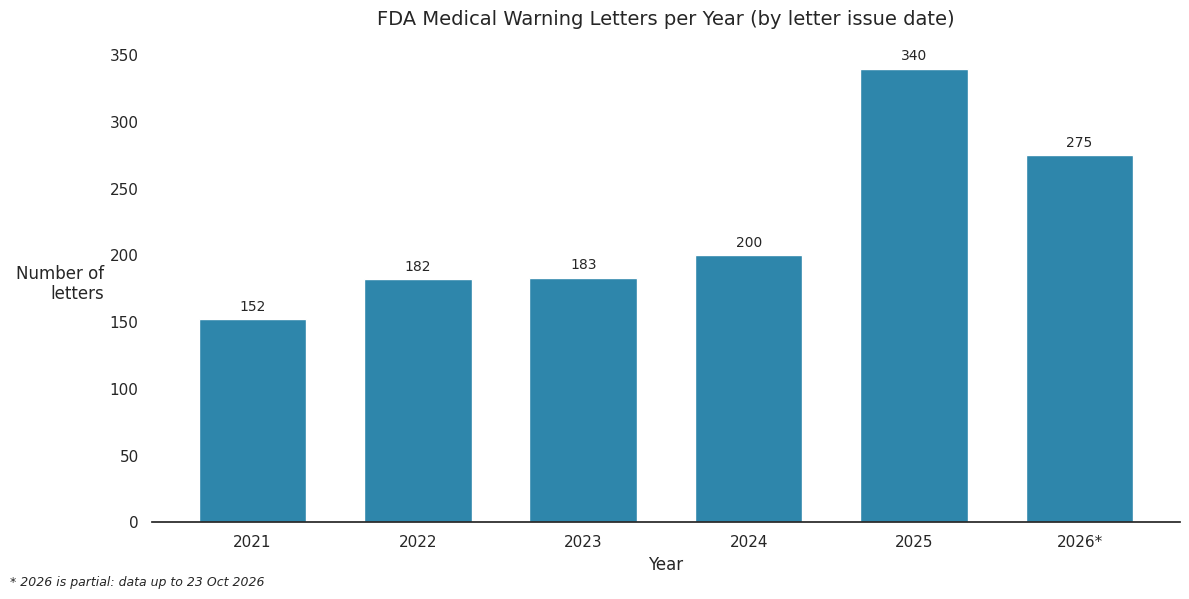

 Year  Count
 2021    152
 2022    182
 2023    183
 2024    200
 2025    340
 2026    275


In [125]:
letters_per_year = (letters["year"].value_counts().sort_index()
                    .reindex(range(YEAR_MIN, YEAR_MAX + 1), fill_value=0)
                    .rename_axis("Year").reset_index(name="Count"))
partial_year = LAST_DATE.year if LAST_DATE.month < 12 else None
labels_x = [f"{y}*" if y == partial_year else str(y) for y in letters_per_year["Year"]]

sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(labels_x, letters_per_year["Count"], color="#2E86AB", width=0.65)
ax.bar_label(bars, padding=4, fontsize=10)
ax.set_title("FDA Medical Warning Letters per Year (by letter issue date)", fontsize=14, pad=15)
ax.set_xlabel("Year")
ax.set_ylabel("Number of\nletters", **HORIZONTAL_YLABEL)
if partial_year:
    fig.text(0.01, 0.01, f"* {partial_year} is partial: data up to {LAST_DATE:%d %b %Y}", fontsize=9, style="italic")
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(letters_per_year.to_string(index=False))

## 4. Dominant Terms (TF-IDF)

### 4.1 מילות עצירה
אותה רשימה של מילים "משפטיות" וקבועות כמו קודם, **חוץ ממילים שמתארות נושא** (`covid`, `sanitizer`, `compounding`, `device`, `hand`...). אותן כבר לא מוחקים, כי הן בדיוק מה שמבדיל בין סוגי מכתבים. נוספו מילים כלליות שעלו בגרף הישן (`including`, `address`, `united`, `states`...).

In [126]:
BOILERPLATE = [
    'fda', 'act', 'letter', 'firm', 'section', 'products', 'product', 'compliance',
    'received', 'response', 'inspections', 'investigations', 'food', 'drug', 'drugs',
    'administration', 'intended', 'use', 'violation', 'violations', 'substance',
    'substances', 'requirements', 'prohibited', 'commerce', 'interstate', 'within',
    'days', 'working', 'office', 'sincerely', 'director', 'center', 'care', 'adulterated',
    'misbranded', 'insanitary', 'conditions', 'cgmp', 'current', 'good', 'manufacturing',
    'practice', 'regulations', 'facility', 'inspection', 'investigator', 'review',
    'observed', 'specific', 'including', 'failure', 'failed', 'establish', 'procedures',
    'written', 'assure', 'identity', 'strength', 'quality', 'purity', 'regulatory',
    'legal', 'action', 'actions', 'address', 'steps', 'taken', 'correct', 'prevent',
    'recurrence', 'conclusions', 'investigate', 'thoroughly', 'unexplained',
    'discrepancy', 'batch', 'component', 'components', 'meet', 'specifications',
    'distributed', 'lots', 'lot', 'testing', 'test', 'results', 'analytical',
    'laboratory', 'records', 'record', 'control', 'controls', 'unit', 'responsibility',
    'authority', 'approve', 'reject', 'refer', 'case', 'number', 'date', 'dated',
    'title', 'label', 'labeling', 'website', 'internet', 'offers', 'sale', 'introduced',
    'solution', 'solutions', 'delivered', 'introduction', 'violates', 'sections',
    'meaning', 'federal', 'cosmetic', 'approved', 'application', 'applications',
    'effect', 'pursuant', 'evident', 'basis', 'legally', 'marketed', 'without',
    'gdufa', 'generic', 'user', 'fee', 'amendments', 'reauthorization', 'fiscal',
    'years', 'iii', 'commitment', 'eligible', 'post', 'meeting', 'obtain',
    'preliminary', 'feedback', 'adequacy', 'completeness', 'plans', 'content',
    'regulated', 'certified', 'medically', 'supervised', 'healthcare', 'setting',
    'hospitals', 'surgical', 'centers', 'emergency', 'departments', 'management',
    'acute', 'pain', 'severe', 'enough', 'require', 'opioid', 'analgesic',
    'alternative', 'treatments', 'inadequate', 'href', 'com', 'b4', 'variant',
    'url', 'http', 'https', 'ampoule', 'www', 'net', 'org', 'dear', 'mr', 'ms',
    'dr', 'attention', 'att', 'warning', 'include', 'unapproved', 'ensure',
    'appropriate', 'new', 'provide', 'process', 'data', 'information',
    'stated', 'noted', 'determine', 'found', 'described', 'regarding',
    'additionally', 'regard', 'follows', 'following', 'referred', 'indicated',
    'requires', 'provides', 'determines', 'available', 'additional', 'conducted',
    'required', 'documents', 'documentation', 'submit', 'submitted', 'copies',
    'copy', 'evidence', 'implementation', 'evaluate', 'evaluation', 'reviewed',
    'assessment', 'necessary', 'time', 'listed', 'items', 'item', 'paragraph',
    'order', 'clearly', 'subject', 'provisions', 'contained', 'issue', 'issued',
    'receive', 'sending', 'sent', 'reply', 'replying', 'contact', 'finally',
    'know', 'bring', 'closeout', 'observations', 'applicable', 'laws', 'serious',
    'problems', 'systems', 'prompt', 'marketing', 'distribute', 'sell', 'sold',
    'distribution', 'commercial', 'cfr', 'part', 'parts', 'subpart', 'title21',
    '21cfr', 'statute', 'did', 'used', 'plan', 'program', 'gov', 'recipient',
    'letters', 'fdca', 'adequate', 'research', 'risk', 'equipment', 'corrective',
    'manufacture', 'limited', 'health', 'treatment', 'person',
    'audit', 'protocol', 'procedure', 'report', 'reports', 'standard', 'standards',
    'method', 'methods', 'parameter', 'parameters', 'specification', 'preventive',
    'capa', 'sop', 'master', 'production', 'operations', 'performed', 'personnel',
    'staff', 'trained', 'training', 'qualification', 'validated', 'released',
    'quarantine', 'sampling', 'sample', 'samples', 'collected', 'collection',
    'analysis', 'analyzed', 'tested', 'tester', 'third', 'party', 'vendor',
    'supplier', 'contract', 'site', 'sites', 'line', 'lines', 'room', 'rooms',
    'area', 'areas', 'zone', 'zones', 'environment', 'environmental',
    'active', 'particular', 'clinical', 'ingredient', 'ingredients',
    'concerning', 'conduct', 'misleading', 'chemical', 'immediate', 'clean',
    'validate', 'validation', 'periodic', 'initial',
    'comprehensive', 'based', 'receipt', 'remediation',
    # added: generic words that topped the old c-TF-IDF chart
    'united', 'states', 'stating', 'addressed', 'paragraphs', 'also', 'however',
    'please', 'company', 'firms', 'may', 'must', 'should', 'would', 'could',
]
# Words that describe a TOPIC are kept on purpose (they were removed before)
TOPIC_WORDS = {'covid', 'coronavirus', 'sanitizer', 'sanitizers', 'compounding',
               'device', 'devices', 'hand'}

base_stop_words = sk_text.ENGLISH_STOP_WORDS.union(BOILERPLATE) - TOPIC_WORDS
print(f"{len(base_stop_words)} stop words")

681 stop words


### 4.2 ניקוי טקסט
כמו קודם: מוחק קישורים, מספרים וסימנים, ומעביר לאותיות קטנות. עובד על גוף המכתב.

In [127]:
def preprocess(text_in):
    text_in = re.sub(r'https?://\S+|www\.\S+', ' ', text_in)
    text_in = re.sub(r'\b\d+\b', ' ', text_in)
    text_in = re.sub(r'[^a-zA-Z\s]', ' ', text_in)
    text_in = re.sub(r'\s+', ' ', text_in).strip()
    return text_in.lower()

clean_texts = [preprocess(t) for t in texts]
print(f"🧹 {len(clean_texts)} texts cleaned.")

🧹 1332 texts cleaned.


### 4.3 TF-IDF על מילים, צמדים ושלשות
וקטורייזר אחד ל-1 עד 3 מילים. הציון של כל מונח הוא סכום ה-TF-IDF שלו בכל המכתבים.
* `max_df=0.60` – מונח שמופיע ביותר מ-60% מהמכתבים הוא נוסח קבוע ונזרק.
* `min_df` – מונח שמופיע בפחות מ-1% מהמכתבים נזרק (רעש).
* `sublinear_tf` – מכתב שחוזר על מילה 40 פעמים לא משתלט על התוצאה.

In [128]:
n_docs = len(clean_texts)
tfidf_terms = TfidfVectorizer(
    stop_words=list(base_stop_words),
    token_pattern=r'\b[a-zA-Z]{4,}\b',
    ngram_range=(1, 3),
    max_df=0.60,
    min_df=max(2, int(n_docs * 0.01)),
    sublinear_tf=True,
    max_features=20000,
)
mat_terms = tfidf_terms.fit_transform(clean_texts)
all_df = pd.DataFrame({
    "Term":   tfidf_terms.get_feature_names_out(),
    "Weight": np.asarray(mat_terms.sum(axis=0)).ravel(),
})
all_df["Type"] = all_df["Term"].str.split().str.len().map({1: "Unigram", 2: "Bigram", 3: "Trigram"})
all_df = all_df.sort_values("Weight", ascending=False).reset_index(drop=True)
print(f"{len(all_df)} terms")

14490 terms


### 4.4 שתי רשימות: חופשית וקלינית
* **רשימה A – חופשית:** 25 המונחים החזקים, בלי שום סינון ידני. זו התמונה "האובייקטיבית".
* **רשימה B – קלינית:** רק מונחים שמכילים שורש קליני/מיקרוביולוגי (`clinical_roots`), חוץ מצירופים ברשימה השחורה. זו התמונה הממוקדת, ובעבודה צריך לכתוב במפורש שהיא תלויה ברשימת השורשים.

בשתי הרשימות: **בלי מכפילים** (הוסרו ה-×1.4 / ×1.8 השרירותיים), וכל מושג מופיע **פעם אחת** (`dedupe_terms`).

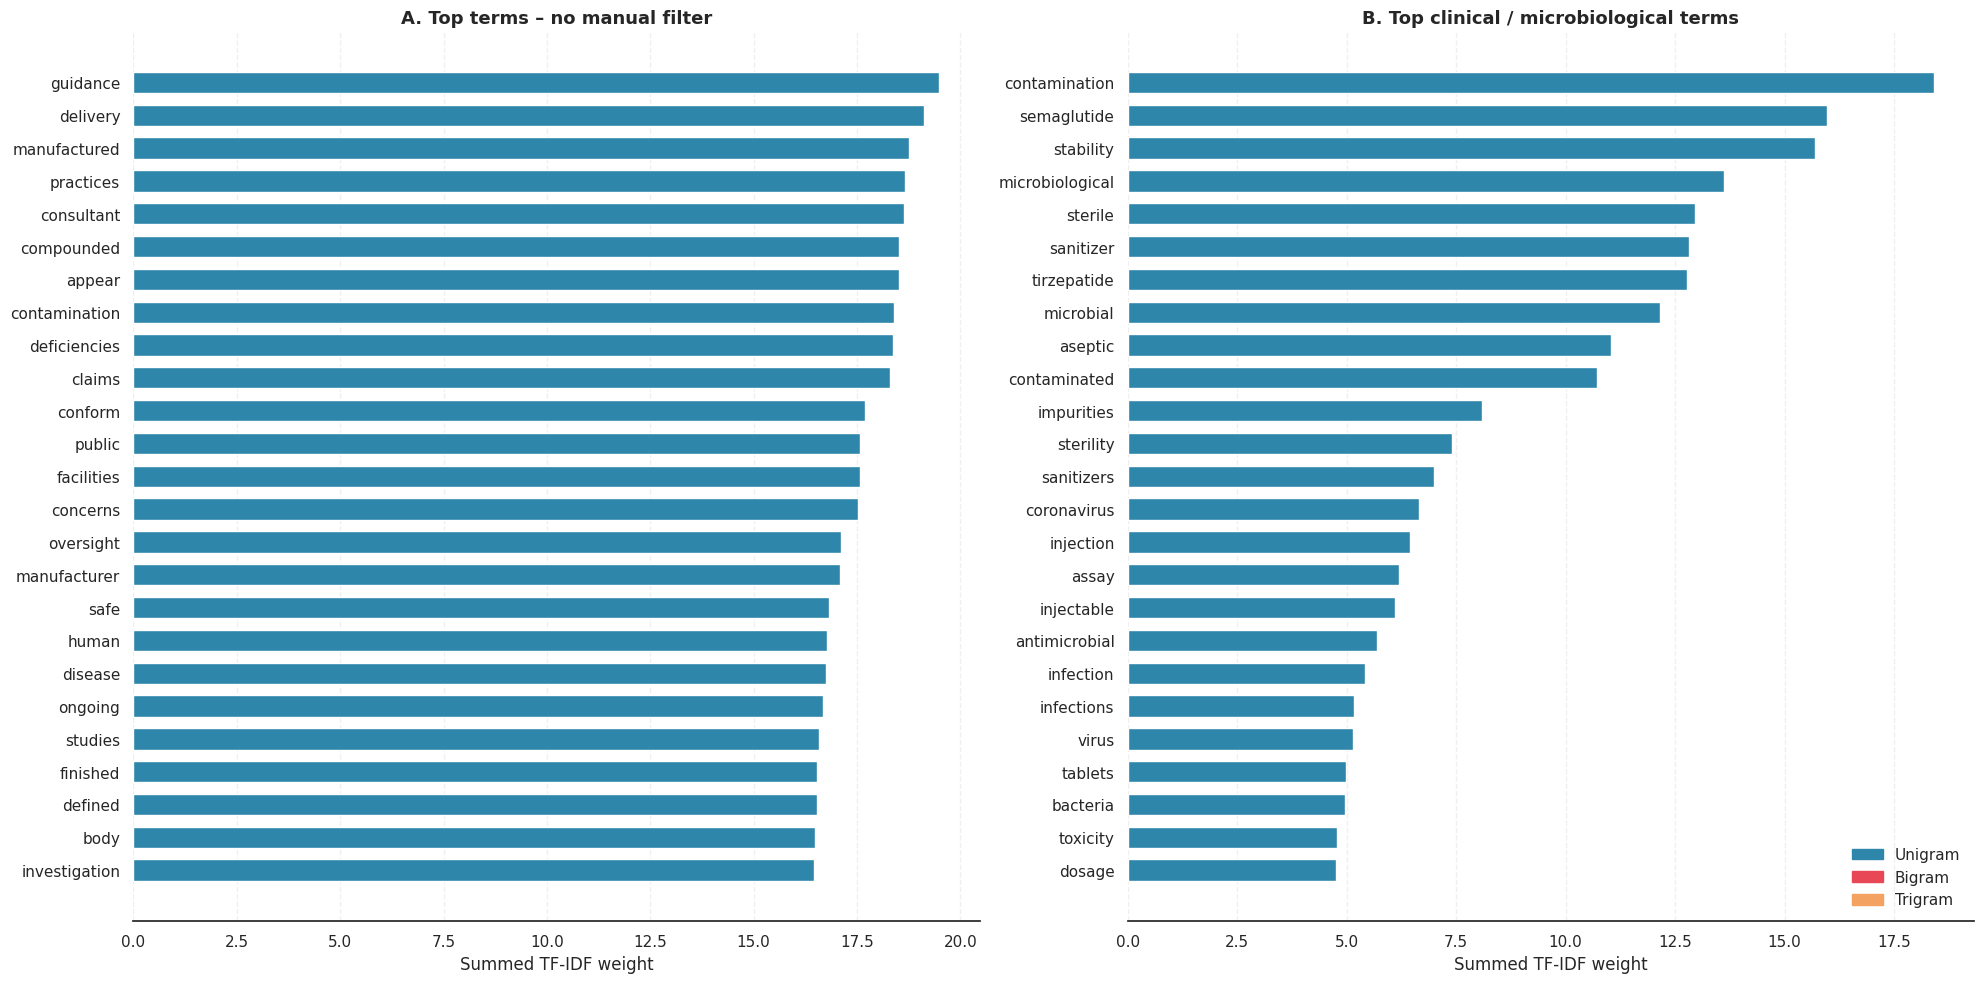

           Term    Type    Weight
  contamination Unigram 18.404869
    semaglutide Unigram 15.961528
      stability Unigram 15.688444
microbiological Unigram 13.625541
        sterile Unigram 12.958933
      sanitizer Unigram 12.818872
    tirzepatide Unigram 12.766674
      microbial Unigram 12.159590
        aseptic Unigram 11.040007
   contaminated Unigram 10.714730
     impurities Unigram  8.079804
      sterility Unigram  7.411323
     sanitizers Unigram  6.985791
    coronavirus Unigram  6.644633
      injection Unigram  6.451927
          assay Unigram  6.187787
     injectable Unigram  6.102345
  antimicrobial Unigram  5.681464
      infection Unigram  5.406872
     infections Unigram  5.168580
          virus Unigram  5.141923
        tablets Unigram  4.989482
       bacteria Unigram  4.958478
       toxicity Unigram  4.778631
         dosage Unigram  4.763421


In [129]:
NGRAM_BLACKLIST = {
    'misleading particular', 'concerning compounded', 'conduct clinical',
    'chemical microbiological', 'clinical studies', 'remediation given',
    'remediated stability', 'contents compoundinginspections', 'compoundinginspections',
    'repreparation', 'given remediation', 'given specific',
}
clinical_roots = [
    'steril', 'contamin', 'microbio', 'semaglu', 'tirzepa', 'infect', 'bacteri',
    'virus', 'viral', 'aseptic', 'impurit', 'validat', 'stabil', 'potenc', 'assay',
    'sanitiz', 'hygien', 'endotoxin', 'pyrogen', 'toxic', 'dosage', 'formulat',
    'capsule', 'tablet', 'inject', 'vial', 'lyophil', 'reconstitut', 'excipient',
    'preservat', 'antibiotic', 'pathogen', 'fungal', 'fungi', 'bioburden',
    'autoclave', 'depyrogenat', 'cleanroom', 'microbial', 'particulat',
]

def is_clinical(term):
    return any(root in term for root in clinical_roots)

def top_unique(df_terms, n=25):
    keep = dedupe_terms(df_terms["Term"].tolist(), n)
    return df_terms.set_index("Term").loc[keep].reset_index()

top_free = top_unique(all_df)
clin = all_df[all_df["Term"].apply(is_clinical) & ~all_df["Term"].isin(NGRAM_BLACKLIST)]
top_clin = top_unique(clin)

type_colors = {"Unigram": "#2E86AB", "Bigram": "#E84855", "Trigram": "#F4A261"}
sns.set_theme(style="white")
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
for ax, df_t, title in [(axes[0], top_free, "A. Top terms – no manual filter"),
                        (axes[1], top_clin, "B. Top clinical / microbiological terms")]:
    ax.barh(df_t["Term"], df_t["Weight"], color=[type_colors[t] for t in df_t["Type"]], height=0.65)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Summed TF-IDF weight")
    ax.xaxis.grid(True, linestyle="--", alpha=0.3)
    sns.despine(ax=ax, left=True)
axes[1].legend(handles=[mpatches.Patch(color=c, label=t) for t, c in type_colors.items()],
               frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print(top_clin[["Term", "Type", "Weight"]].to_string(index=False))

## 5. Topic Clustering with K-Means

### 5.1 מטריצת TF-IDF
כל מכתב הופך לשורה של מספרים (ציון לכל מילה וצמד מילים). אותה מטריצה משמשת גם לשמות הקבוצות בסעיף 7.

In [130]:
tfidf = TfidfVectorizer(
    stop_words=list(base_stop_words),
    token_pattern=r'\b[a-zA-Z]{4,}\b',
    ngram_range=(1, 2),
    max_df=0.60,
    min_df=5,
    sublinear_tf=True,
)
tfidf_matrix = tfidf.fit_transform(clean_texts)
feature_names = tfidf.get_feature_names_out()
print(f"TF-IDF matrix: {tfidf_matrix.shape[0]} letters × {tfidf_matrix.shape[1]} terms")

TF-IDF matrix: 1332 letters × 19944 terms


### 5.2 כמה קבוצות? (Silhouette)
**Silhouette** מודד כמה כל מכתב קרוב לקבוצה שלו לעומת הקבוצה השכנה. הטווח הוא בין ‎-1 ל-1, וגבוה יותר = חלוקה ברורה יותר. מריצים K-Means ל-k=2..8 ובוחרים את ה-k עם הציון הגבוה.

אם רוצים מספר אחר מסיבה מוצדקת (למשל 3 כדי להשוות לעבודה קודמת), כותבים אותו ב-`K_KMEANS_OVERRIDE` ומסבירים בעבודה.

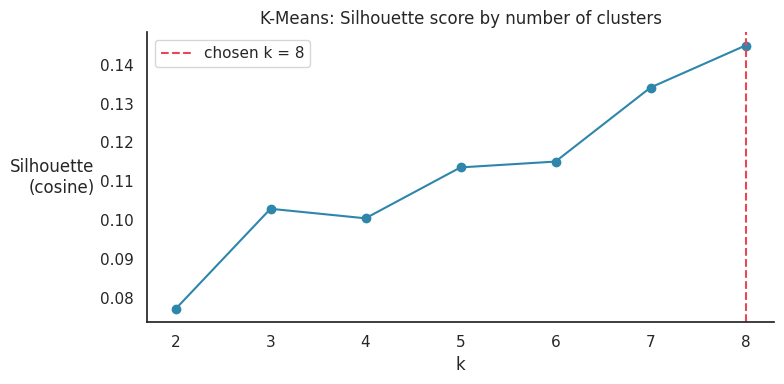

{2: np.float64(0.077), 3: np.float64(0.103), 4: np.float64(0.1), 5: np.float64(0.114), 6: np.float64(0.115), 7: np.float64(0.134), 8: np.float64(0.145)}


In [131]:
K_RANGE = range(2, 9)
K_KMEANS_OVERRIDE = None

sil_kmeans = {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(tfidf_matrix)
    sil_kmeans[k] = silhouette_score(tfidf_matrix, km.labels_, metric="cosine")

K_KMEANS = K_KMEANS_OVERRIDE or max(sil_kmeans, key=sil_kmeans.get)

plt.figure(figsize=(8, 4))
plt.plot(list(sil_kmeans), list(sil_kmeans.values()), marker="o", color="#2E86AB")
plt.axvline(K_KMEANS, color="#E84855", linestyle="--", label=f"chosen k = {K_KMEANS}")
plt.title("K-Means: Silhouette score by number of clusters")
plt.xlabel("k"); plt.ylabel("Silhouette\n(cosine)", **HORIZONTAL_YLABEL); plt.legend(); sns.despine()
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in sil_kmeans.items()})

### 5.3 אימון K-Means ותיאור הקבוצות
השמות נוצרים **אוטומטית** מהמילים המבדלות, ולכל קבוצה מודפס מה ה-FDA כתב בשדה הנושא של המכתבים שבה.

In [132]:
kmeans = KMeans(n_clusters=K_KMEANS, random_state=RANDOM_STATE, n_init=10).fit(tfidf_matrix)
kmeans_labels = kmeans.labels_
letters["kmeans_cluster"] = kmeans_labels + 1

kmeans_dist  = distinctive_terms(kmeans_labels, tfidf_matrix, feature_names)
kmeans_names = cluster_names(kmeans_dist)
cluster_profile(kmeans_labels, kmeans_names)


📁 C1: covid · coronavirus · treat diagnose  —  56 letters
   FDA subject lines:
       64%  Unapproved and Misbranded Products Related to Coronavirus Disease 2019 (COVID-19)
       12%  Unapproved New Drug Products Related to Coronavirus Disease 2019 (COVID-19)
        7%  Unapproved and Misbranded Product Related to Coronavirus Disease 2019 (COVID-19)
   Example companies: About Mineral; Ageless Global, LLC; Allure Imports; Alternative Health Distribution LLC d/b/a CannaAid

📁 C2: incoming · finished · stability  —  326 letters
   FDA subject lines:
       73%  CGMP/Finished Pharmaceuticals/Adulterated
        5%  Nonprescription/OTC
        4%  CGMP/Finished Pharmaceuticals/Unapproved New Drug/Misbranded/Adulterated
   Example companies: ABBE Laboratories, Inc.; Absolutely Natural; Accra-Pac, Inc. dba Voyant Beauty; Accupack Midwest, Inc.

📁 C3: compounded · semaglutide · tirzepatide  —  112 letters
   FDA subject lines:
       51%  Unlawful Sale of Unapproved and Misbranded Drugs t

### 5.3.1 יציבות K-Means
K-Means תלוי בנקודת ההתחלה. כאן מריצים אותו שוב על **אותה** מטריצת TF-IDF, עם אותו `K_KMEANS` ועם 10 ערכי `random_state` (0–9, `n_init=10`), ומחשבים Adjusted Rand Index בין כל זוג ריצות וגם מול הריצה הראשית של המחברת (`RANDOM_STATE`). ARI של 1 פירושו אותה חלוקה, ו-0 פירושו לא יותר טוב ממקרי.

מספרי האשכולות לא תואמים בין ריצות (אשכול 1 בזרע אחד הוא לא אשכול 1 בזרע אחר), ולכן טבלת הגדלים ממוינת מהגדול לקטן בכל ריצה.

In [133]:
STABILITY_SEEDS = list(range(10))


def pairwise_ari(runs):
    return np.array([adjusted_rand_score(runs[i], runs[j])
                     for i in range(len(runs)) for j in range(i + 1, len(runs))])


def stability_band(value):
    if value >= 0.8:
        return "stable"
    if value >= 0.5:
        return "moderately stable"
    return "unstable"


km_runs = [KMeans(n_clusters=K_KMEANS, random_state=seed, n_init=10).fit_predict(tfidf_matrix)
           for seed in STABILITY_SEEDS]
pair_ari = pairwise_ari(km_runs)
vs_main = np.array([adjusted_rand_score(kmeans_labels, lab) for lab in km_runs])

print(f"K-Means on TF-IDF, k = {K_KMEANS}, {len(STABILITY_SEEDS)} seeds, n_init = 10")
print(f"ARI between runs: mean {pair_ari.mean():.3f} | min {pair_ari.min():.3f} | max {pair_ari.max():.3f}")
print(f"ARI vs the main run (random_state = {RANDOM_STATE}): "
      f"mean {vs_main.mean():.3f} | min {vs_main.min():.3f} | max {vs_main.max():.3f}")

size_table = pd.DataFrame(
    {f"seed {seed}": sorted(np.bincount(lab), reverse=True) for seed, lab in zip(STABILITY_SEEDS, km_runs)},
    index=[f"largest" if i == 0 else f"{i + 1}" for i in range(K_KMEANS)])
display(size_table)
print("ARI ≥ 0.8 = stable, 0.5–0.8 = moderately stable, < 0.5 = unstable")
print(f"The TF-IDF K-Means solution is {stability_band(pair_ari.mean())} "
      f"(mean pairwise ARI {pair_ari.mean():.2f}).")


K-Means on TF-IDF, k = 8, 10 seeds, n_init = 10
ARI between runs: mean 0.764 | min 0.559 | max 1.000
ARI vs the main run (random_state = 42): mean 0.780 | min 0.608 | max 0.996


,seed 0,seed 1,seed 2,seed 3,seed 4,seed 5,seed 6,seed 7,seed 8,seed 9
largest,386,490,385,461,462,499,490,386,491,490
2,272,389,300,263,287,361,389,328,304,389
3,224,107,257,224,204,123,107,234,141,107
4,142,82,112,107,107,93,82,112,107,82
5,111,75,82,82,82,88,75,82,89,75
6,82,72,75,75,75,61,72,75,82,72
7,59,61,65,64,59,55,61,59,61,61
8,56,56,56,56,56,52,56,56,57,56


ARI ≥ 0.8 = stable, 0.5–0.8 = moderately stable, < 0.5 = unstable
The TF-IDF K-Means solution is moderately stable (mean pairwise ARI 0.76).


### 5.4 ציור הקבוצות (TruncatedSVD)
TruncatedSVD מכווץ את מטריצת ה-TF-IDF ל-2 ממדים **רק לציור**. החלוקה עצמה נעשתה במרחב המלא.

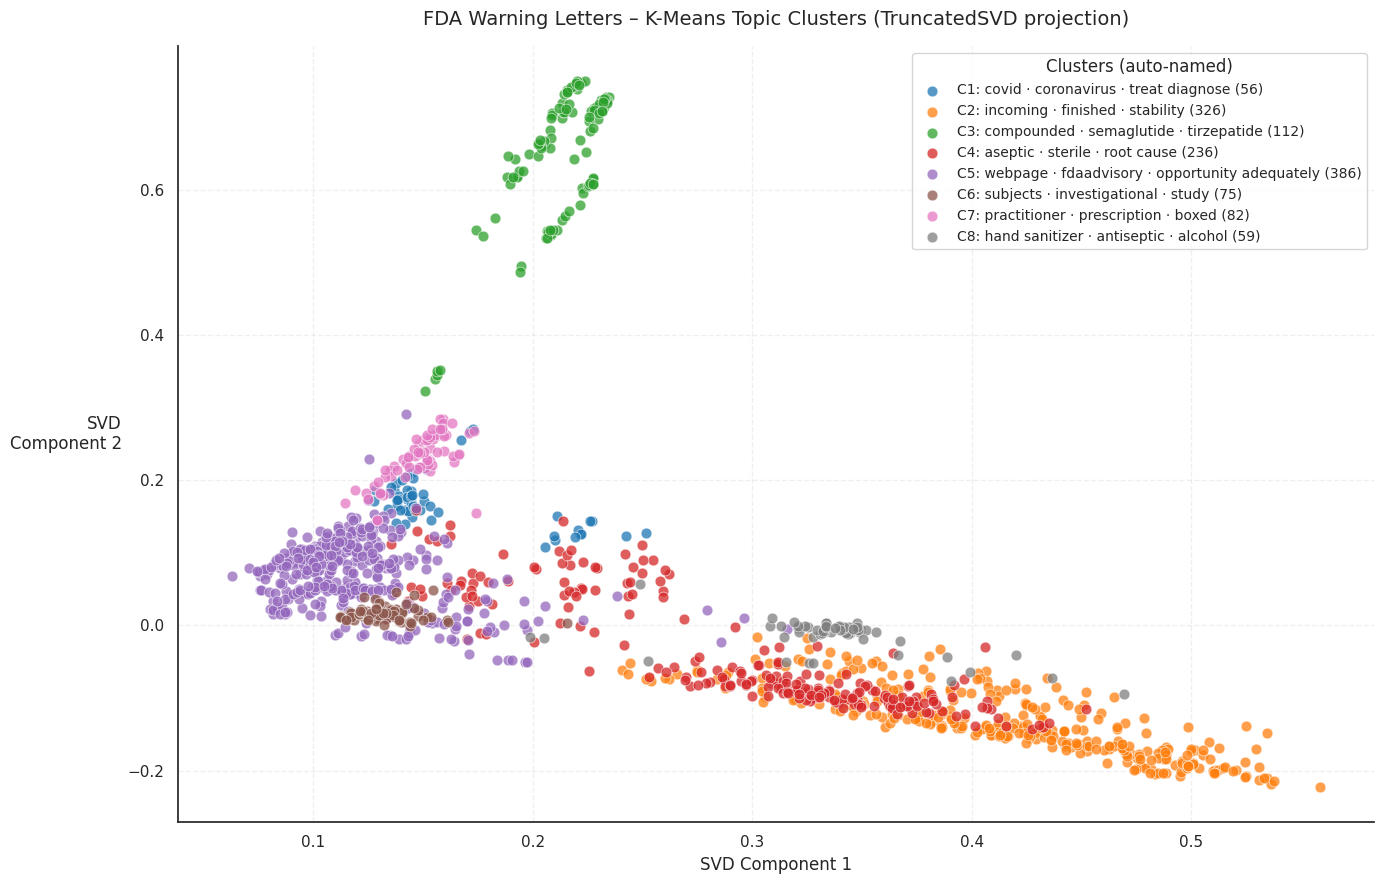

In [134]:
svd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE)
svd_xy = svd.fit_transform(tfidf_matrix)
km_colors = sns.color_palette("tab10", K_KMEANS)

sns.set_theme(style="white")
plt.figure(figsize=(14, 9))
for c in range(K_KMEANS):
    m = kmeans_labels == c
    plt.scatter(svd_xy[m, 0], svd_xy[m, 1], color=km_colors[c], alpha=0.75,
                edgecolors="w", s=60, linewidths=0.5, label=f"{kmeans_names[c]} ({m.sum()})")
plt.title("FDA Warning Letters – K-Means Topic Clusters (TruncatedSVD projection)", fontsize=14, pad=15)
plt.xlabel("SVD Component 1"); plt.ylabel("SVD\nComponent 2", **HORIZONTAL_YLABEL)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(title="Clusters (auto-named)", fontsize=10, loc="best")
sns.despine(); plt.tight_layout(); plt.show()

## 6. Semantic Clustering with Sentence-BERT

### 6.1 וקטור לכל מכתב – על **כל** המכתב
המודל `all-MiniLM-L6-v2` קורא עד 256 טוקנים (~200 מילים). לכן:
1. כל מכתב מחולק לקטעים של 150 מילים (עד 20 קטעים = 3,000 מילים).
2. כל קטע הופך לווקטור.
3. הווקטור של המכתב = הממוצע של הקטעים שלו.

כך הווקטור מייצג את התוכן של כל המכתב, ולא רק את הפתיחה. ב-GPU זה לוקח כמה דקות.

In [135]:
WORDS_PER_CHUNK = 150
MAX_CHUNKS = 20

def clean_for_embedding(t):
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def word_chunks(t, n=WORDS_PER_CHUNK):
    w = t.split()
    return [" ".join(w[i:i + n]) for i in range(0, len(w), n)] or [""]

chunk_texts, chunk_owner = [], []
for i, t in enumerate(texts):
    parts = word_chunks(clean_for_embedding(t))[:MAX_CHUNKS]
    chunk_texts += parts
    chunk_owner += [i] * len(parts)
chunk_owner = np.array(chunk_owner)
print(f"🧠 {len(chunk_texts)} chunks ({len(chunk_texts) / len(texts):.1f} per letter)")

sbert_model = SentenceTransformer("all-MiniLM-L6-v2")
chunk_emb = sbert_model.encode(chunk_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

embeddings = np.vstack([chunk_emb[chunk_owner == i].mean(axis=0) for i in range(len(texts))])
embeddings /= np.linalg.norm(embeddings, axis=1, keepdims=True)
print(f"✅ Embedding matrix: {embeddings.shape}")

🧠 17427 chunks (13.1 per letter)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/273 [00:00<?, ?it/s]

✅ Embedding matrix: (1332, 384)


### 6.2 עץ היררכי (Ward) ובחירת מספר הקבוצות
בונים את העץ פעם אחת, חותכים אותו ל-k=2..8 ובודקים Silhouette לכל חיתוך. גם כאן אפשר לקבוע מספר ידנית עם `K_SEMANTIC_OVERRIDE`.

**חשוב:** זו החלוקה היחידה של סעיפים 6–7. בגרסה הקודמת היו שתי חלוקות שונות (טקסט נקי וטקסט גולמי), ולכן "קבוצה 1" לא הייתה אותה קבוצה בשני הסעיפים.

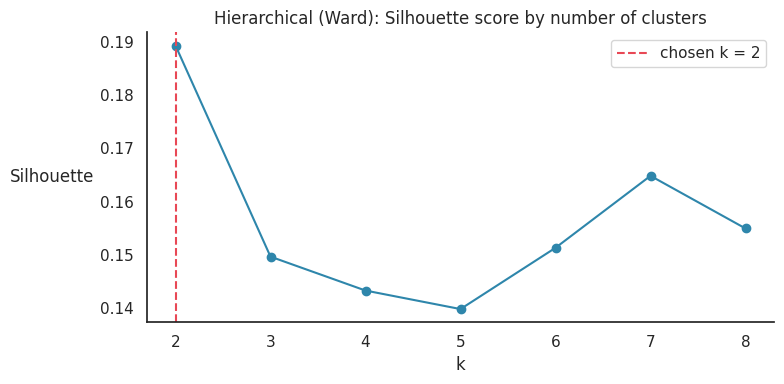

{2: np.float32(0.189), 3: np.float32(0.15), 4: np.float32(0.143), 5: np.float32(0.14), 6: np.float32(0.151), 7: np.float32(0.165), 8: np.float32(0.155)}
Cluster sizes: [503, 829]


In [136]:
Z = linkage(embeddings, method="ward")
K_SEMANTIC_OVERRIDE = None

sil_ward = {k: silhouette_score(embeddings, fcluster(Z, t=k, criterion="maxclust"))
            for k in K_RANGE}
K_SEMANTIC = K_SEMANTIC_OVERRIDE or max(sil_ward, key=sil_ward.get)
hier_labels = fcluster(Z, t=K_SEMANTIC, criterion="maxclust") - 1
letters["semantic_cluster"] = hier_labels + 1

plt.figure(figsize=(8, 4))
plt.plot(list(sil_ward), list(sil_ward.values()), marker="o", color="#2E86AB")
plt.axvline(K_SEMANTIC, color="#E84855", linestyle="--", label=f"chosen k = {K_SEMANTIC}")
plt.title("Hierarchical (Ward): Silhouette score by number of clusters")
plt.xlabel("k"); plt.ylabel("Silhouette", **HORIZONTAL_YLABEL); plt.legend(); sns.despine()
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in sil_ward.items()})
print("Cluster sizes:", np.bincount(hier_labels).tolist())

### 6.2.1 יציבות החלוקה הסמנטית
ההשוואה הזו יושבת כאן, ולא בסעיף 5.3, כי ה-embeddings נוצרים רק בסעיף 6.

חלוקת Ward על ה-embeddings של Sentence-BERT דטרמיניסטית: אין בה זרע אקראי, ולכן ה-ARI שלה הוא 1.0 מעצם הבנייה. להשוואה מריצים K-Means על **אותם** embeddings, עם `k = K_SEMANTIC` ואותם 10 זרעים כמו בסעיף 5.3.1. זה לא מחליף את חלוקת Ward.

In [137]:
print("Ward on the SBERT embeddings is deterministic, so its ARI is 1.0 by construction.")

sem_km_runs = [KMeans(n_clusters=K_SEMANTIC, random_state=seed, n_init=10).fit_predict(embeddings)
               for seed in STABILITY_SEEDS]
sem_pair = pairwise_ari(sem_km_runs)
print(f"K-Means on the SBERT embeddings, k = {K_SEMANTIC}, same {len(STABILITY_SEEDS)} seeds, n_init = 10")
print(f"ARI between runs: mean {sem_pair.mean():.3f} | min {sem_pair.min():.3f} | max {sem_pair.max():.3f}")
sem_sizes = pd.DataFrame(
    {f"seed {seed}": sorted(np.bincount(lab), reverse=True) for seed, lab in zip(STABILITY_SEEDS, sem_km_runs)},
    index=[f"largest" if i == 0 else f"{i + 1}" for i in range(K_SEMANTIC)])
display(sem_sizes)
print("ARI ≥ 0.8 = stable, 0.5–0.8 = moderately stable, < 0.5 = unstable")
print(f"K-Means on the SBERT embeddings is {stability_band(sem_pair.mean())} "
      f"(mean pairwise ARI {sem_pair.mean():.2f}).")


Ward on the SBERT embeddings is deterministic, so its ARI is 1.0 by construction.
K-Means on the SBERT embeddings, k = 2, same 10 seeds, n_init = 10
ARI between runs: mean 0.999 | min 0.997 | max 1.000


,seed 0,seed 1,seed 2,seed 3,seed 4,seed 5,seed 6,seed 7,seed 8,seed 9
largest,681,681,681,680,681,681,681,681,681,681
2,651,651,651,652,651,651,651,651,651,651


ARI ≥ 0.8 = stable, 0.5–0.8 = moderately stable, < 0.5 = unstable
K-Means on the SBERT embeddings is stable (mean pairwise ARI 1.00).


## 7. Keywords per Semantic Cluster + Maps

### 7.1 המילים המבדלות של כל קבוצה (במקום c-TF-IDF)
**למה ה-c-TF-IDF הישן נכשל:** הוא חיבר כל קבוצה למסמך אחד והריץ TF-IDF על 3 מסמכים בלבד. עם 3 מסמכים, מילה שמופיעה בכל הקבוצות נענשת רק פי 1.7 בערך, ולכן מילים כלליות שמופיעות הרבה (`including`, `address`, `https`) ניצחו.

**הציון החדש:** לכל מילה, הממוצע שלה במכתבים של הקבוצה **פחות** הממוצע שלה בשאר המכתבים. מילה שנפוצה בכל מקום מקבלת כמעט אפס. השמות של הקבוצות נגזרים מהציון הזה, ולא נכתבים ידנית.

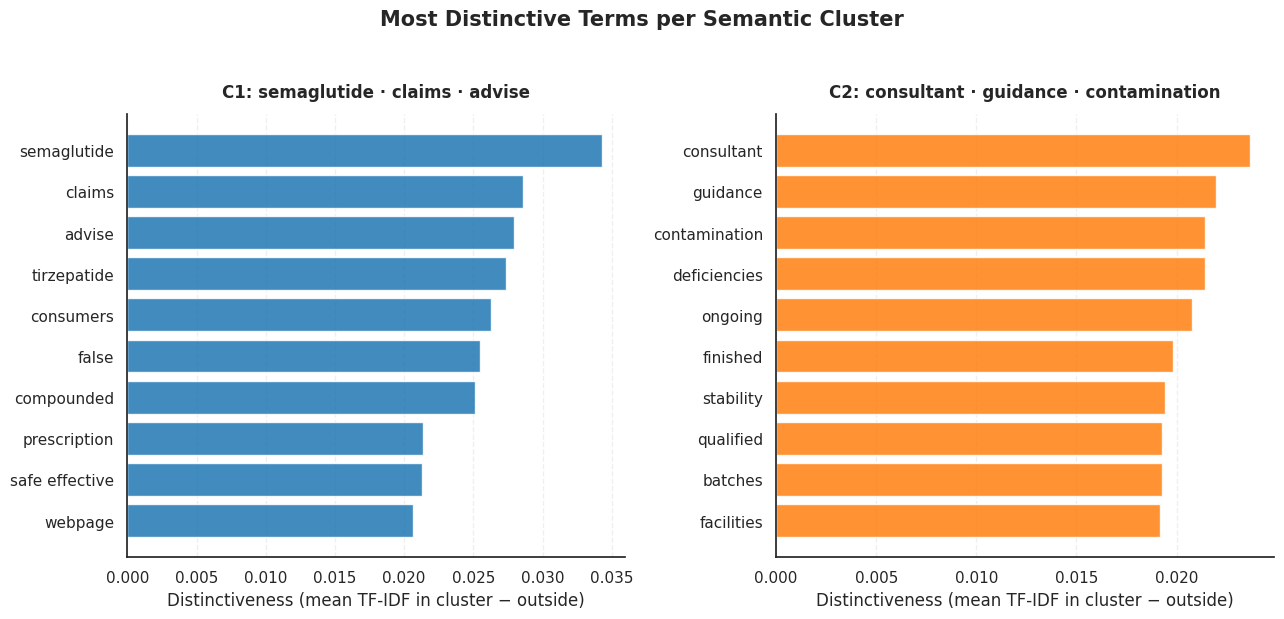


📁 C1: semaglutide · claims · advise  —  503 letters
   FDA subject lines:
       22%  Unapproved New Drugs/Misbranded
       11%  False & Misleading Claims/Misbranded (Telehealth)
       10%  Unlawful Sale of Unapproved and Misbranded Drugs to United States Consumers Over the Inter
   Example companies: 123Herbals; 247rxpill.in; 24HrDoc, Inc. dba 24HrDoc; 7Tabz Retail, LLC

📁 C2: consultant · guidance · contamination  —  829 letters
   FDA subject lines:
       43%  CGMP/Finished Pharmaceuticals/Adulterated
        7%  Compounding Pharmacy/Adulterated Drug Products
        6%  CGMP/Active Pharmaceutical Ingredient (API)/Adulterated
   Example companies: 3D Imaging Drug Design and Development LLC; 4U Health; AAA Cosmetica, SA de CV; AACE Pharmaceuticals, Inc.


In [138]:
sem_dist   = distinctive_terms(hier_labels, tfidf_matrix, feature_names)
sem_names  = cluster_names(sem_dist)
sem_colors = sns.color_palette("tab10", K_SEMANTIC)

plot_distinctive(sem_dist, sem_names, "Most Distinctive Terms per Semantic Cluster", sem_colors)
cluster_profile(hier_labels, sem_names)

### 7.2 מפת t-SNE + דנדרוגרמה
* **שמאל – t-SNE:** כל נקודה היא מכתב. נקודות קרובות = מכתבים דומים. המרחק בין "איים" שונים וגודל האיים **לא** אומרים כלום.
* **ימין – דנדרוגרמה:** העץ. הגובה של כל חיבור = כמה הקבוצות שונות. הקו המקווקו הוא המקום שבו העץ נחתך. המספרים בסוגריים = כמה מכתבים בכל ענף.

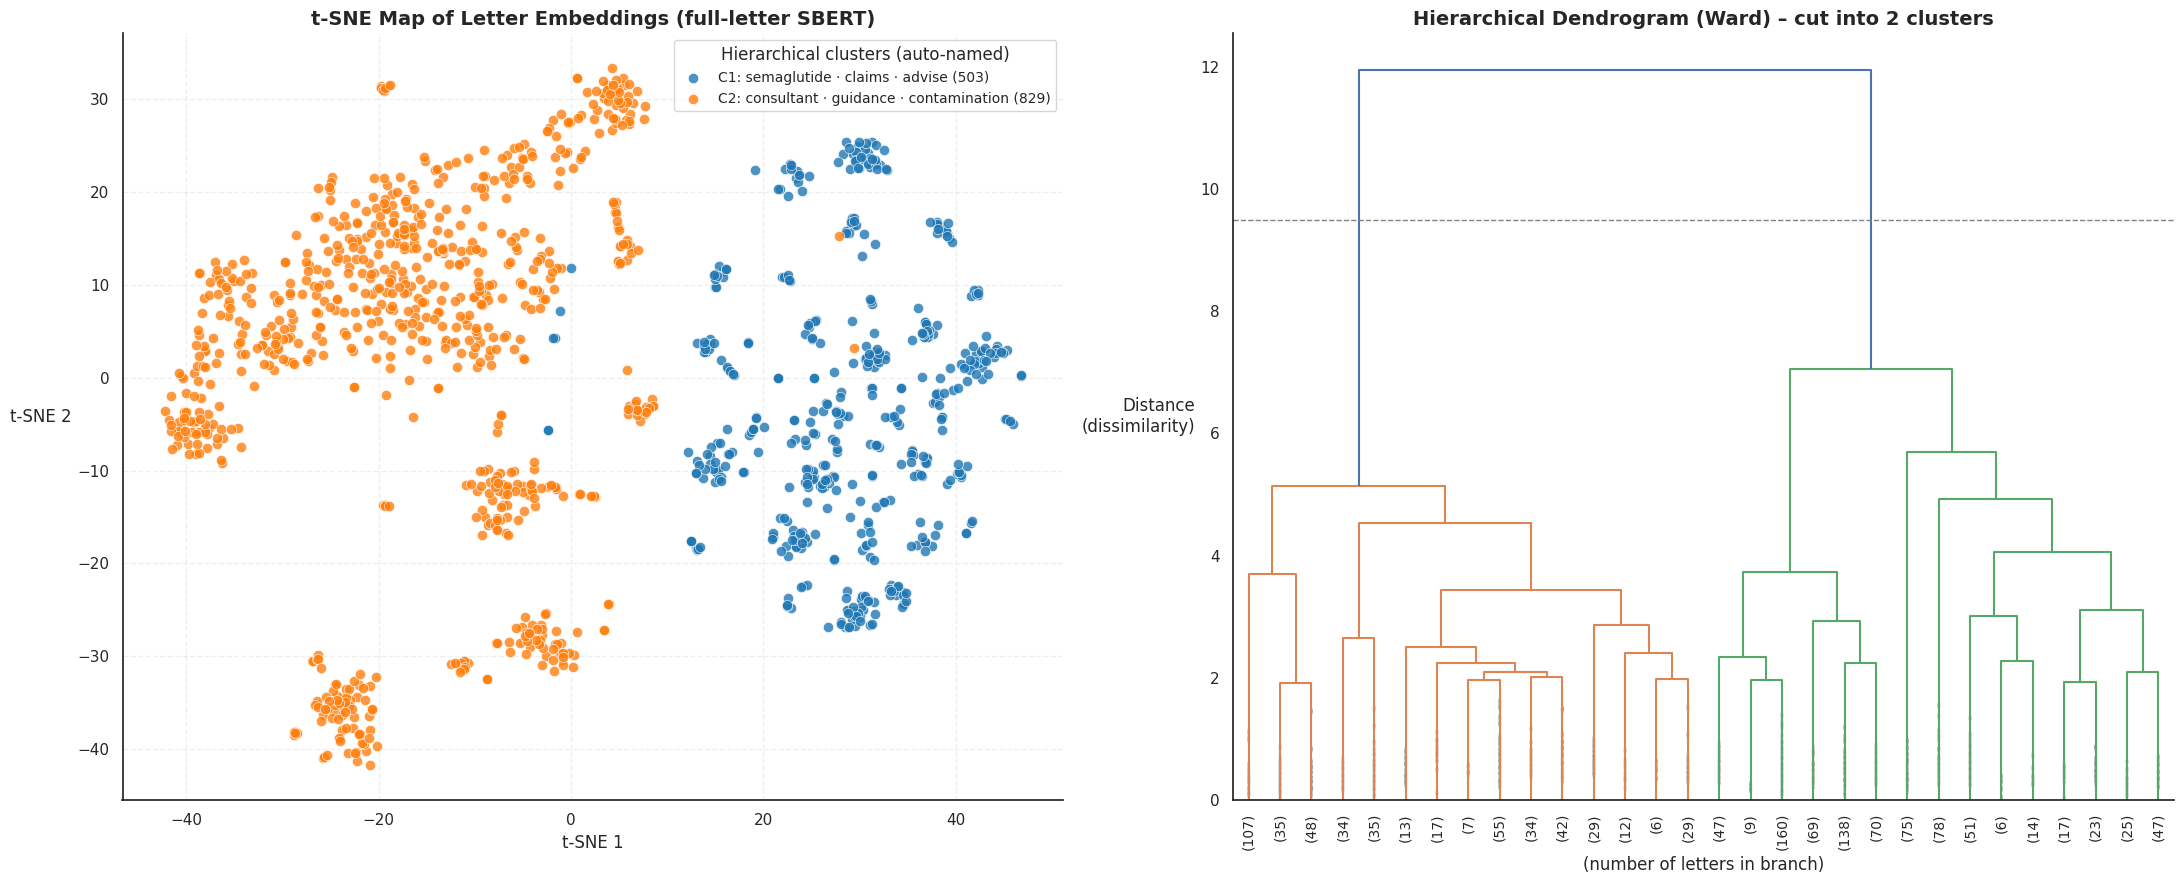

In [139]:
tsne_xy = TSNE(n_components=2, perplexity=30, init="random",
               random_state=RANDOM_STATE, max_iter=1000).fit_transform(embeddings)

sns.set_theme(style="white")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))
for c in range(K_SEMANTIC):
    m = hier_labels == c
    ax1.scatter(tsne_xy[m, 0], tsne_xy[m, 1], color=sem_colors[c], alpha=0.8,
                edgecolors="w", s=55, linewidths=0.5, label=f"{sem_names[c]} ({m.sum()})")
ax1.set_title("t-SNE Map of Letter Embeddings (full-letter SBERT)", fontsize=14, fontweight="bold")
ax1.set_xlabel("t-SNE 1"); ax1.set_ylabel("t-SNE 2", **HORIZONTAL_YLABEL)
ax1.grid(True, linestyle="--", alpha=0.3)
ax1.legend(title="Hierarchical clusters (auto-named)", fontsize=10, loc="best")
sns.despine(ax=ax1)

cut = (Z[-K_SEMANTIC, 2] + Z[-(K_SEMANTIC - 1), 2]) / 2
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax2, leaf_rotation=90,
           leaf_font_size=10, show_contracted=True, color_threshold=cut)
ax2.axhline(cut, color="grey", linestyle="--", linewidth=1)
ax2.set_title(f"Hierarchical Dendrogram (Ward) – cut into {K_SEMANTIC} clusters", fontsize=14, fontweight="bold")
ax2.set_xlabel("(number of letters in branch)"); ax2.set_ylabel("Distance\n(dissimilarity)", **HORIZONTAL_YLABEL)
sns.despine(ax=ax2)
plt.tight_layout(); plt.show()

### 7.3 האם שתי השיטות מסכימות?
טבלה של קבוצות K-Means מול הקבוצות הסמנטיות. אם רוב המכתבים של קבוצה אחת נופלים בקבוצה אחת של השיטה השנייה, שתי השיטות מצאו את אותו נושא, וזו ראיה חזקה שהנושא אמיתי.

In [140]:
display(pd.crosstab(letters["kmeans_cluster"].map(lambda c: kmeans_names[c - 1]),
                    letters["semantic_cluster"].map(lambda c: sem_names[c - 1]),
                    rownames=["K-Means"], colnames=["Semantic (SBERT)"]))

Semantic (SBERT),C1: semaglutide · claims · advise,C2: consultant · guidance · contamination
K-Means,,
C1: covid · coronavirus · treat diagnose,56,0
C2: incoming · finished · stability,2,324
C3: compounded · semaglutide · tirzepatide,107,5
C4: aseptic · sterile · root cause,2,234
C5: webpage · fdaadvisory · opportunity adequately,254,132
C6: subjects · investigational · study,0,75
C7: practitioner · prescription · boxed,82,0
C8: hand sanitizer · antiseptic · alcohol,0,59


## 8. Zero-Shot Classification with DeBERTa

### 8.1 GPU וטעינת המודל
בלי GPU השלב הזה איטי מאוד. ב-Colab: Runtime → Change runtime type → T4 GPU.

In [141]:
if torch.cuda.is_available():
    device = 0
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = -1
print("⚠️ No GPU – this section will be slow" if device == -1 else f"🚀 GPU detected ({device})")
classifier = pipeline("zero-shot-classification",
                      model="MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli", device=device)

🚀 GPU detected (0)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

### 8.2 קטגוריות וחלוקה לקטעים
* **הקטגוריות עודכנו לפי הנושאים הרשמיים של ה-FDA.** בגרסה הקודמת 3 מתוך 5 קטגוריות קיבלו יחד 6 מכתבים. בשדה הנושא של ה-FDA כמעט אין מכתבים על "safety reports" או "data integrity", אבל יש עשרות מכתבים על **Compounding** (רקיחה בבתי מרקחת), שלא הייתה לו קטגוריה. לכן יש עכשיו 4 קטגוריות: cGMP, תרופות לא מאושרות / שיווק מטעה, Compounding ומחקר קליני.
* כל קטגוריה מוכנסת למשפט (`HYPOTHESIS`), וזה עוזר למודל.
* **פיצול לקטעים:** הטקסט שהורד מופרד ב-`\n` בודד ולא ב-`\n\n`, ולכן בגרסה הקודמת כל מכתב היה "פסקה" אחת, ורק 1,000 התווים הראשונים (הכותרת) סווגו. עכשיו גוף המכתב מחולק לקטעים של עד 1,000 תווים, ומסווגים עד 8 קטעים לכל מכתב. הקוד מדפיס כמה קטעים יצאו בממוצע, כדי לוודא שהפיצול עובד.
* **הצבעה:** כל קטגוריה שעוברת סף 0.5 בקטע מקבלת קול. מנצחת הקטגוריה עם הכי הרבה קולות. בתיקו מנצחת הקטגוריה עם הציון הממוצע הגבוה.

In [142]:
TOPICS = {
    "manufacturing quality and cGMP violations":       "cGMP & Manufacturing Quality",
    "unapproved drugs, misbranding and false claims":  "Unapproved Drugs & Misbranding",
    "pharmacy drug compounding":                       "Drug Compounding",
    "clinical trials and research violations":         "Clinical & Research Violations",
}
UNCLASSIFIED = "Unclassified"
HYPOTHESIS = "This FDA warning letter paragraph is about {}."
THRESHOLD = 0.5
MAX_CHUNKS_PER_LETTER = 8

def paragraph_chunks(body, min_chars=200, max_chars=1000):
    pieces = []
    for line in body.split("\n"):
        line = line.strip()
        while len(line) > max_chars:
            cut = line.rfind(" ", 0, max_chars)
            cut = cut if cut > 0 else max_chars
            pieces.append(line[:cut]); line = line[cut:].strip()
        if line:
            pieces.append(line)
    chunks, cur = [], ""
    for p in pieces:
        if cur and len(cur) + len(p) + 1 > max_chars:
            chunks.append(cur); cur = p
        else:
            cur = f"{cur} {p}".strip()
        if len(cur) >= min_chars and len(cur) >= max_chars * 0.8:
            chunks.append(cur); cur = ""
    if cur:
        chunks.append(cur)
    return chunks

cls_texts, cls_owner = [], []
for i, b in enumerate(letters["body"]):
    parts = paragraph_chunks(b)[:MAX_CHUNKS_PER_LETTER]
    cls_texts += parts
    cls_owner += [i] * len(parts)
cls_owner = np.array(cls_owner)
chunks_per_letter = np.bincount(cls_owner, minlength=len(letters))
print(f"{len(cls_texts)} chunks to classify ({chunks_per_letter.mean():.1f} per letter)")
print(f"Letters with only 1 chunk: {(chunks_per_letter == 1).sum()} | with 0 chunks: {(chunks_per_letter == 0).sum()}")

10504 chunks to classify (7.9 per letter)
Letters with only 1 chunk: 0 | with 0 chunks: 0


### 8.3 הסיווג – עם קטגוריית "לא רלוונטי" ופסקאות ראיה
* **תווית חמישית – "לא רלוונטי".** הרבה קטעים במכתב לא מתארים הפרה בכלל: איך בוצעה הבדיקה, איך עונים למכתב, זכויות ערעור, פרטי קשר. בגרסה הקודמת גם הקטעים האלה הצביעו, ולכן נוסף למודל תיאור חמישי (`IRRELEVANT`) שמועבר יחד עם 4 הנושאים: *"instructions on how to respond to this letter, contact information, or legal rights"*.
* **למה הניסוח הזה:** הניסוח הראשון היה עם שלילה (*"general procedural or legal text that does not describe a specific violation"*). מודלי NLI מתקשים עם שלילה, והוא סימן 78% מהקטעים כלא רלוונטיים: 281 מכתבים נשארו Unclassified וההסכמה עם נושא ה-FDA ירדה מ-89% ל-70%. במדגם של 150 מכתבים נבדקו 6 ניסוחים. ניסוחים חיוביים (שמתארים **מה כן** נמצא בקטע) השאירו 56%–81% מהקטעים רלוונטיים, בלי לפגוע בהסכמה (88%–89%), ונבחר הניסוח שמתאר בדיוק את סוגי הטקסט שרוצים לסנן. לא נבחר ניסוח עם "the inspection process", כי פסקאות על הבדיקה מכילות לעיתים קרובות את ההפרות עצמן.
* **מי מצביע:** קטע נחשב **רלוונטי** רק אם הציון הגבוה ביותר שלו באחד מ-4 הנושאים גבוה מהציון של "לא רלוונטי". קטעים לא רלוונטיים לא מצביעים. כלל ההצבעה עצמו לא השתנה (סף 0.5, רוב קולות, ובתיקו הציון הממוצע הגבוה), אבל הוא מופעל רק על הקטעים הרלוונטיים. שמות 4 הנושאים וערכי `final_topic` נשארו זהים, כך שכל התאים הבאים רצים בלי שינוי.
* **ציונים לכל מכתב:** לכל נושא נשמר הציון הממוצע על הקטעים הרלוונטיים (עמודות `score: ...`), וגם מספר הקטעים הרלוונטיים (`relevant_chunks`).
* **ראיות:** לכל מכתב שסווג נשמרים 3 הקטעים הרלוונטיים עם הציון הגבוה ביותר לנושא שנבחר (`classification_evidence.csv`), והקטע הראשון (400 תווים) נכנס לעמודה `evidence`. כך אפשר להראות **למה** המודל בחר בנושא.
* **שמירה ו-cache:** כל הציונים ברמת הקטע נשמרים ב-`chunk_scores.csv` (שם חדש, כדי שה-cache הישן של 4 התוויות לא ייטען בטעות). בהרצה הבאה קטע שהטקסט שלו זהה לשמור נטען מהקובץ, ורק קטעים חדשים (למשל מכתבים חדשים שה-FDA פרסם) או קטעים שהשתנו נשלחים למודל. עם `multi_label=True` המודל נותן ציון **נפרד** לכל תווית, ולכן ה-cache נשמר לכל תווית בנפרד: אם משנים תווית אחת, רק היא מחושבת מחדש. כדי לכפות סיווג מלא מחדש מגדירים `RECLASSIFY = True`.

In [143]:
CHUNK_SCORES_OUT = DATA_DIR / "chunk_scores.csv"
CLASSIFIED_OUT   = DATA_DIR / "letters_classified.csv"
EVIDENCE_OUT     = DATA_DIR / "classification_evidence.csv"
RECLASSIFY = False
N_EVIDENCE = 3

IRRELEVANT = "instructions on how to respond to this letter, contact information, or legal rights"
topic_list = list(TOPICS)
all_labels = topic_list + [IRRELEVANT]
SCORE_COLS = {t: f"score: {TOPICS[t]}" for t in topic_list}
KEY = ["url", "chunk", "text"]

chunk_df = pd.DataFrame({"url": letters["url"].to_numpy()[cls_owner],
                         "chunk": pd.Series(cls_owner).groupby(cls_owner).cumcount().to_numpy(),
                         "text": cls_texts})

cached = pd.read_csv(CHUNK_SCORES_OUT, keep_default_na=False) if CHUNK_SCORES_OUT.exists() and not RECLASSIFY else None
reused = [lab for lab in all_labels if cached is not None and lab in cached.columns]
if reused:
    chunk_df = chunk_df.merge(cached[KEY + reused].drop_duplicates(KEY), on=KEY, how="left")
for lab in all_labels:
    if lab not in chunk_df:
        chunk_df[lab] = np.nan

BATCH = 128
for lab in all_labels:
    todo = np.flatnonzero(chunk_df[lab].isna().to_numpy())
    if len(todo) == 0:
        continue
    print(f"🔎 Scoring {len(todo)} of {len(chunk_df)} chunks for: {lab}")
    new_scores = np.zeros(len(todo))
    for s in tqdm(range(0, len(todo), BATCH), desc=TOPICS.get(lab, "irrelevant"), leave=False):
        out = classifier([cls_texts[i] for i in todo[s:s + BATCH]], candidate_labels=[lab],
                         multi_label=True, hypothesis_template=HYPOTHESIS, batch_size=16)
        out = [out] if isinstance(out, dict) else out
        new_scores[s:s + len(out)] = [res["scores"][0] for res in out]
    chunk_df.loc[todo, lab] = new_scores
print(f"📂 Scores reused from {CHUNK_SCORES_OUT.name} for {len(reused)} of {len(all_labels)} labels "
      "(only new or changed chunks were scored)")

scores = chunk_df[topic_list].to_numpy(float)
relevant = scores.max(axis=1) > chunk_df[IRRELEVANT].to_numpy(float)
chunk_df["relevant"] = relevant
chunk_df.to_csv(CHUNK_SCORES_OUT, index=False)

final_topic, evidence_rows = [], []
mean_scores = np.full((len(letters), len(topic_list)), np.nan)
n_relevant = np.zeros(len(letters), dtype=int)
for i in range(len(letters)):
    rows = np.flatnonzero((cls_owner == i) & relevant)
    n_relevant[i] = len(rows)
    if len(rows) == 0:
        final_topic.append(UNCLASSIFIED); continue
    s = scores[rows]
    mean_scores[i] = s.mean(axis=0)
    votes = (s >= THRESHOLD).sum(axis=0)
    if votes.max() == 0:
        final_topic.append(UNCLASSIFIED); continue
    tied = np.flatnonzero(votes == votes.max())
    t = tied[np.argmax(mean_scores[i][tied])]
    final_topic.append(topic_list[t])
    for rank, r in enumerate(rows[np.argsort(-s[:, t], kind="stable")][:N_EVIDENCE], start=1):
        evidence_rows.append({"url": letters.at[i, "url"], "topic": topic_list[t], "rank": rank,
                              "score": round(float(scores[r, t]), 4), "text": cls_texts[r]})

letters["final_topic"] = final_topic
letters["relevant_chunks"] = n_relevant
for k, t in enumerate(topic_list):
    letters[SCORE_COLS[t]] = mean_scores[:, k].round(4)
evidence_df = pd.DataFrame(evidence_rows, columns=["url", "topic", "rank", "score", "text"])
evidence_df.to_csv(EVIDENCE_OUT, index=False)
letters["evidence"] = letters["url"].map(
    evidence_df[evidence_df["rank"] == 1].set_index("url")["text"].str[:400]).fillna("")
letters.drop(columns=["text"]).to_csv(CLASSIFIED_OUT, index=False)

print(f"Irrelevant chunks: {(~relevant).mean():.1%} of {len(relevant)} chunks (they do not vote)")
print(f"Letters with no relevant chunk at all: {(n_relevant == 0).sum()}\n")
print(letters["final_topic"].value_counts().to_string())

full_evidence = evidence_df.loc[evidence_df["rank"] == N_EVIDENCE, "url"]
example = letters[letters["url"].isin(full_evidence)].sample(1, random_state=RANDOM_STATE).iloc[0]
print(f"\n📄 Example: {example['company']} ({example['date']:%Y-%m-%d})")
print(f"   FDA subject:      {example['subject']}")
print(f"   DeBERTa category: {TOPICS[example['final_topic']]}")
for _, row in evidence_df[evidence_df["url"] == example["url"]].iterrows():
    print(f"\n   [{row['rank']}] score {row['score']:.2f}\n   {row['text'][:700]}")

📂 Scores reused from chunk_scores.csv for 5 of 5 labels (only new or changed chunks were scored)
Irrelevant chunks: 23.8% of 10504 chunks (they do not vote)
Letters with no relevant chunk at all: 2

final_topic
unapproved drugs, misbranding and false claims    588
manufacturing quality and cGMP violations         572
pharmacy drug compounding                          90
clinical trials and research violations            76
Unclassified                                        6

📄 Example: Salon Technologies International, Inc. (2022-12-21)
   FDA subject:      CGMP/Finished Pharmaceuticals/Adulterated
   DeBERTa category: cGMP & Manufacturing Quality

   [1] score 1.00
   Your firm failed to conduct impurity testing, including acetal, acetaldehyde, and benzene, of active pharmaceutical ingredients or for your finished hand sanitizer drug products prior to distribution. Because these impurities are a known risk of the manufacturing process, a finished product specification for these impu

### 8.4 בדיקת דיוק מול הנושא הרשמי של ה-FDA
כאן משתמשים בשדה `subject` שה-FDA עצמו כתב לכל מכתב, והופכים אותו לקטגוריית ייחוס לפי מילות מפתח.

* זה **ייחוס משוער**: שדה הנושא לפעמים מכיל כמה נושאים (למשל `CGMP/Finished Pharmaceuticals/Unapproved New Drug/Misbranded`). במקרה כזה הקטגוריה נקבעת לפי הסדר: קליני → Compounding → cGMP → תרופות לא מאושרות / misbranding.
* המילים `Finished Pharmaceuticals` לבדן **לא** נחשבות cGMP. בגרסה הקודמת הן כן נחשבו, ולכן כ-100 מכתבים מסוג `Finished Pharmaceuticals/Unapproved New Drug/Misbranded` סומנו בטעות כ-cGMP.
* מכתבים שהנושא שלהם לא מתאים לאף כלל (למשל `Nonprescription/OTC`, ‏`HCT/Ps`, ‏`Failure to Register and List`) לא נכנסים לבדיקה.
* הקוד מדפיס את הנושאים הנפוצים, כדי שתוכל לבדוק שהכללים הגיוניים.

In [144]:
SUBJECT_RULES = [
    ("clinical trials and research violations",        r"clinical|investigator|sponsor|bioresearch|\birb\b|institutional review|bioequivalence"),
    ("pharmacy drug compounding",                      r"compounding|outsourcing"),
    ("manufacturing quality and cGMP violations",      r"cgmp|good manufacturing|active pharmaceutical|\bapi\b"),
    ("unapproved drugs, misbranding and false claims", r"misbrand|unapproved|new drug|false|misleading|labeling|internet|online"),
]

def subject_to_topic(subj):
    s = str(subj).lower()
    for topic, pattern in SUBJECT_RULES:
        if re.search(pattern, s):
            return topic
    return None

print("Most common FDA subject lines:")
print(letters["subject"].value_counts().head(15).to_string(), "\n")

letters["reference_topic"] = letters["subject"].apply(subject_to_topic)
ev = letters[letters["reference_topic"].notna()]
print(f"Letters with a reference label: {len(ev)} of {len(letters)} ({len(ev) / len(letters):.0%})")
print(f"Agreement of DeBERTa with the FDA subject: {(ev['final_topic'] == ev['reference_topic']).mean():.1%}\n")
print(classification_report(ev["reference_topic"], ev["final_topic"], zero_division=0))
display(pd.crosstab(ev["reference_topic"], ev["final_topic"],
                    rownames=["FDA subject"], colnames=["DeBERTa"]))

Most common FDA subject lines:
subject
CGMP/Finished Pharmaceuticals/Adulterated                                                                     363
Unapproved New Drugs/Misbranded                                                                               113
Compounding Pharmacy/Adulterated Drug Products                                                                 59
Unlawful Sale of Unapproved and Misbranded Drugs to United States Consumers Over the Internet (Telehealth)     58
False & Misleading Claims/Misbranded (Telehealth)                                                              55
Finished Pharmaceuticals/Unapproved New Drug/Misbranded                                                        49
CGMP/Active Pharmaceutical Ingredient (API)/Adulterated                                                        47
Deviations/CFR/Regulations for Human Cells, Tissues & Cellular Products (HCT/Ps)                               40
Nonprescription/OTC                              

DeBERTa,clinical trials and research violations,manufacturing quality and cGMP violations,pharmacy drug compounding,"unapproved drugs, misbranding and false claims"
FDA subject,,,,
clinical trials and research violations,73,0,0,0
manufacturing quality and cGMP violations,0,495,1,39
pharmacy drug compounding,0,29,31,0
"unapproved drugs, misbranding and false claims",2,9,58,462


### 8.4b בדיקה ידנית (מומלץ להגנה)
שדה הנושא הוא ייחוס משוער, ולכן כדאי לבדוק גם ידנית מדגם קטן:
1. התא מייצא 40 מכתבים אקראיים ל-`manual_check.csv`, עם הקישור, הנושא של ה-FDA והסיווג של DeBERTa.
2. פותחים את הקובץ באקסל, קוראים כל מכתב (הקישור), וממלאים בעמודה `manual_topic` את הקטגוריה הנכונה. השמות המותרים מודפסים מתחת לתא.
3. מריצים שוב את התא: אם העמודה מלאה, הוא מחשב את הדיוק של DeBERTa מול הבדיקה הידנית.

In [145]:
MANUAL_OUT = DATA_DIR / "manual_check.csv"

if not MANUAL_OUT.exists():
    sample = letters.sample(min(40, len(letters)), random_state=RANDOM_STATE)
    sample[["url", "company", "subject", "final_topic"]].assign(manual_topic="").to_csv(MANUAL_OUT, index=False)
    print(f"📝 Wrote {len(sample)} letters to {MANUAL_OUT} – fill in 'manual_topic' and run this cell again.")
    print("Allowed values:", topic_list + [UNCLASSIFIED])
else:
    manual = pd.read_csv(MANUAL_OUT, dtype={"manual_topic": str})
    manual["manual_topic"] = manual["manual_topic"].fillna("").str.strip()
    manual = manual[manual["manual_topic"] != ""]
    if manual.empty:
        print(f"'{MANUAL_OUT}' exists but 'manual_topic' is still empty.")
    else:
        acc = (manual["final_topic"] == manual["manual_topic"]).mean()
        print(f"✅ DeBERTa accuracy vs manual labels: {acc:.0%} on {len(manual)} letters")
        display(pd.crosstab(manual["manual_topic"], manual["final_topic"], rownames=["Manual"], colnames=["DeBERTa"]))

'data/manual_check.csv' exists but 'manual_topic' is still empty.


### 8.5 מגמות לפי שנה – במספרים ובאחוזים
* **שמאל:** מספר מכתבים מכל קטגוריה בכל שנה.
* **ימין:** **אחוז** מכלל המכתבים של אותה שנה. זה הגרף שמראה אם סדרי העדיפויות השתנו, כי הוא מנטרל את העובדה שבשנים מסוימות פשוט היו יותר מכתבים.
* לכל קטגוריה צבע קבוע משלה, והמקרא לפי השמות האמיתיים.

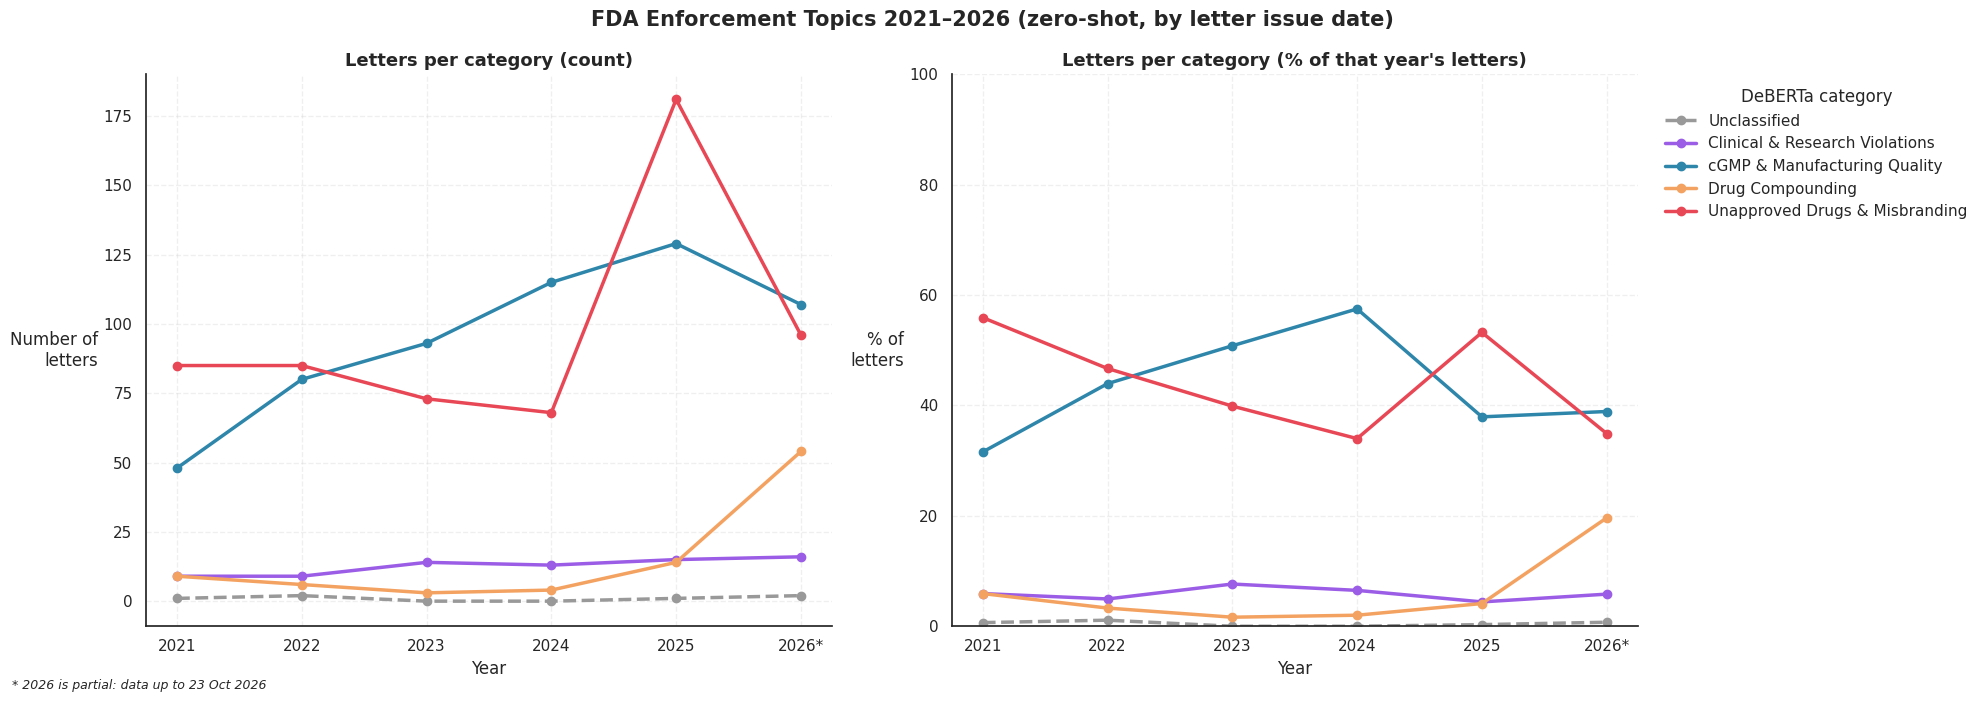

Share of letters per year (%):
final_topic  Unclassified  Clinical & Research Violations  cGMP & Manufacturing Quality  Drug Compounding  Unapproved Drugs & Misbranding
year                                                                                                                                     
2021                  1.0                             6.0                          32.0               6.0                            56.0
2022                  1.0                             5.0                          44.0               3.0                            47.0
2023                  0.0                             8.0                          51.0               2.0                            40.0
2024                  0.0                             6.0                          57.0               2.0                            34.0
2025                  0.0                             4.0                          38.0               4.0                            53.0
202

In [146]:
TOPIC_COLORS = {
    "manufacturing quality and cGMP violations":       "#2E86AB",
    "unapproved drugs, misbranding and false claims":  "#E84855",
    "pharmacy drug compounding":                       "#F4A261",
    "clinical trials and research violations":         "#9B5DE5",
    UNCLASSIFIED:                                      "#999999",
}
DISPLAY = {**TOPICS, UNCLASSIFIED: "Unclassified"}
years = list(range(YEAR_MIN, YEAR_MAX + 1))

yearly_counts = pd.crosstab(letters["year"], letters["final_topic"]).reindex(years, fill_value=0)
yearly_share = yearly_counts.div(yearly_counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
xt = [f"{y}*" if y == partial_year else str(y) for y in years]

sns.set_theme(style="white")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(20, 7))
for col in yearly_counts.columns:
    style = dict(color=TOPIC_COLORS.get(col, "black"), marker="o", linewidth=2.5,
                 linestyle="--" if col == UNCLASSIFIED else "-", label=DISPLAY.get(col, col))
    a1.plot(xt, yearly_counts[col].values, **style)
    a2.plot(xt, yearly_share[col].values, **style)
a1.set_title("Letters per category (count)", fontsize=13, fontweight="bold")
a1.set_ylabel("Number of\nletters", **HORIZONTAL_YLABEL)
a2.set_title("Letters per category (% of that year's letters)", fontsize=13, fontweight="bold")
a2.set_ylabel("% of\nletters", **HORIZONTAL_YLABEL); a2.set_ylim(0, 100)
for a in (a1, a2):
    a.set_xlabel("Year"); a.grid(True, linestyle="--", alpha=0.3); sns.despine(ax=a)
a2.legend(title="DeBERTa category", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.suptitle("FDA Enforcement Topics 2021–2026 (zero-shot, by letter issue date)", fontsize=15, fontweight="bold")
if partial_year:
    fig.text(0.01, 0.01, f"* {partial_year} is partial: data up to {LAST_DATE:%d %b %Y}", fontsize=9, style="italic")
plt.tight_layout()
plt.savefig(DATA_DIR / "fda_yearly_enforcement_trends.png", dpi=300, bbox_inches="tight")
plt.show()

print("Share of letters per year (%):")
print(yearly_share.round(0).rename(columns=DISPLAY).to_string())

### 8.5.1 What drives the anomalies? (year × K-Means cluster)

kmeans_cluster,C1: covid · coronavirus · treat diagnose,C2: incoming · finished · stability,C3: compounded · semaglutide · tirzepatide,C4: aseptic · sterile · root cause,C5: webpage · fdaadvisory · opportunity adequately,C6: subjects · investigational · study,C7: practitioner · prescription · boxed,C8: hand sanitizer · antiseptic · alcohol
year,,,,,,,,
2021,26,14,0,25,29,9,2,47
2022,26,38,0,39,57,7,6,9
2023,4,62,0,22,70,14,9,2
2024,0,80,0,36,64,13,6,1
2025,0,79,57,54,98,15,37,0
2026,0,53,55,60,68,17,22,0


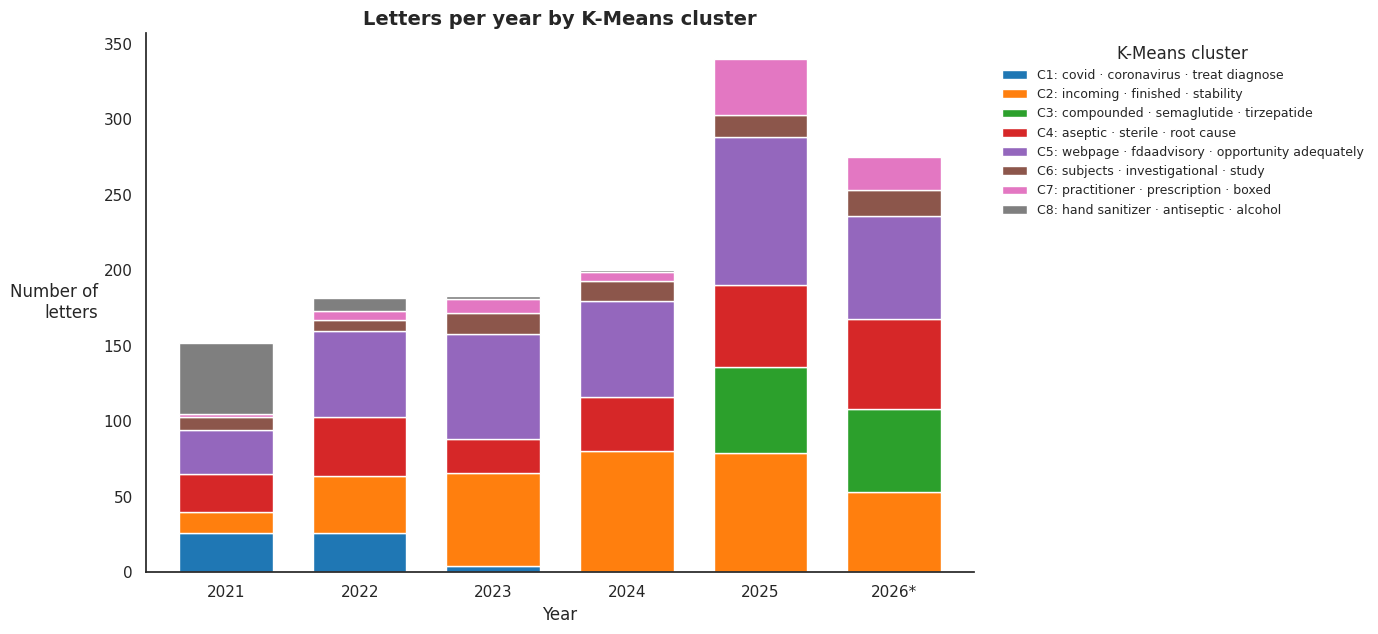

What drove the 2024 → 2025 jump?

By DeBERTa category:
final_topic
Unapproved Drugs & Misbranding    113
cGMP & Manufacturing Quality       14
Drug Compounding                   10
Clinical & Research Violations      2
Unclassified                        1

By K-Means cluster:
kmeans_cluster
C3: compounded · semaglutide · tirzepatide            57
C5: webpage · fdaadvisory · opportunity adequately    34
C7: practitioner · prescription · boxed               31
C4: aseptic · sterile · root cause                    18
C6: subjects · investigational · study                 2
C1: covid · coronavirus · treat diagnose               0
C2: incoming · finished · stability                   -1
C8: hand sanitizer · antiseptic · alcohol             -1


In [147]:
year_cluster = (pd.crosstab(letters["year"], letters["kmeans_cluster"].map(lambda c: kmeans_names[c - 1]))
                .reindex(years, fill_value=0))
display(year_cluster)

ax = year_cluster.plot(kind="bar", stacked=True, figsize=(14, 6.5), width=0.7,
                       color=km_colors[:year_cluster.shape[1]], edgecolor="white", linewidth=1)
ax.set_xticklabels(xt, rotation=0)
ax.set_title("Letters per year by K-Means cluster", fontsize=14, fontweight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("Number of\nletters", **HORIZONTAL_YLABEL)
ax.legend(title="K-Means cluster", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=9)
sns.despine(); plt.tight_layout()
plt.savefig(DATA_DIR / "fda_year_by_cluster.png", dpi=300, bbox_inches="tight")
plt.show()

print("What drove the 2024 → 2025 jump?")
print("\nBy DeBERTa category:")
print((yearly_counts.loc[2025] - yearly_counts.loc[2024]).rename(DISPLAY).sort_values(ascending=False).to_string())
print("\nBy K-Means cluster:")
print((year_cluster.loc[2025] - year_cluster.loc[2024]).sort_values(ascending=False).to_string())

### 8.5.3 ציר זמן חודשי עם החלקת LOWESS
הגרפים השנתיים (8.5) מסתירים מה קורה **בתוך** השנה. כאן בונים סדרה חודשית מינואר 2021 ועד **החודש המלא האחרון** (החודש האחרון, שבו הנתונים נעצרים באמצע, מושמט כדי שלא ייראה כמו ירידה מלאכותית). חודש בלי מכתבים מקבל 0.

* **סדרות:** סך הכול, כל קטגוריית DeBERTa, האחוז של כל קטגוריה מתוך מכתבי אותו חודש, וכל אשכול K-Means.
* **החלקה:** סדרות חודשיות רועשות מאוד, ולכן כל סדרה מוחלקת ב-**LOWESS** (רגרסיה מקומית משוקללת, `statsmodels`). `LOWESS_FRAC` קובע איזה חלק מהנקודות משמש לכל אומדן מקומי (ברירת מחדל 0.25 = בערך 17 חודשים). ערך קטן יותר = קו עוקב יותר אחרי שינויים קצרים.
* **איור 1:** (a) סך הכול לחודש (עמודות) + LOWESS; (b) מספר מכתבים לכל קטגוריה – הקו הדק והחיוור הוא הנתון הגולמי והקו העבה הוא LOWESS; (c) האחוז המוחלק של כל קטגוריה (0–100).
* **איור 2:** LOWESS של מספר המכתבים בכל אשכול K-Means.
* **טבלת סיכום:** ממוצע מכתבים לחודש וממוצע אחוז ב-12 החודשים הראשונים לעומת 12 האחרונים, וחודש השיא. זו התשובה לשאלה של הבוחן: האם נושא גדל **רק במספר** (כי סך המכתבים גדל), או **גם בחלק היחסי** (כלומר סדרי העדיפויות של ה-FDA השתנו).
* **הערה:** ה-FDA מפרסם מכתבים שבועות אחרי תאריך ההוצאה שלהם, ולכן החודשים האחרונים עשויים להיות מעט חסרים גם אחרי השמטת החודש החלקי.
* **`it=0`:** ברירת המחדל של `lowess` מפעילה איטרציות robustness, והן נכשלות בסדרה שרובה אפסים עם כמה קפיצות (אשכול ה-GLP-1 ואשכול ה-COVID). אז הקו העבה קופץ חזרה לערך הגולמי. עם `it=0` ההחלקה חלה על כל הסדרות.


LOWESS uses it=0 (no robustness iterations), frac = 0.25


,max raw,max LOWESS
kmeans_cluster,,
C1: covid · coronavirus · treat diagnose,12,3.4
C2: incoming · finished · stability,12,7.2
C3: compounded · semaglutide · tirzepatide,57,8.8
C4: aseptic · sterile · root cause,9,7.4
C5: webpage · fdaadvisory · opportunity adequately,17,8.6
C6: subjects · investigational · study,4,1.9
C7: practitioner · prescription · boxed,18,3.4
C8: hand sanitizer · antiseptic · alcohol,8,5.9


GLP-1 cluster 'C3: compounded · semaglutide · tirzepatide': max raw month = 57, max smoothed = 8.8
📅 69 full months: Jan 2021 – Sep 2026 (data ends 23 Oct 2026; 23 letters from the partial month dropped)


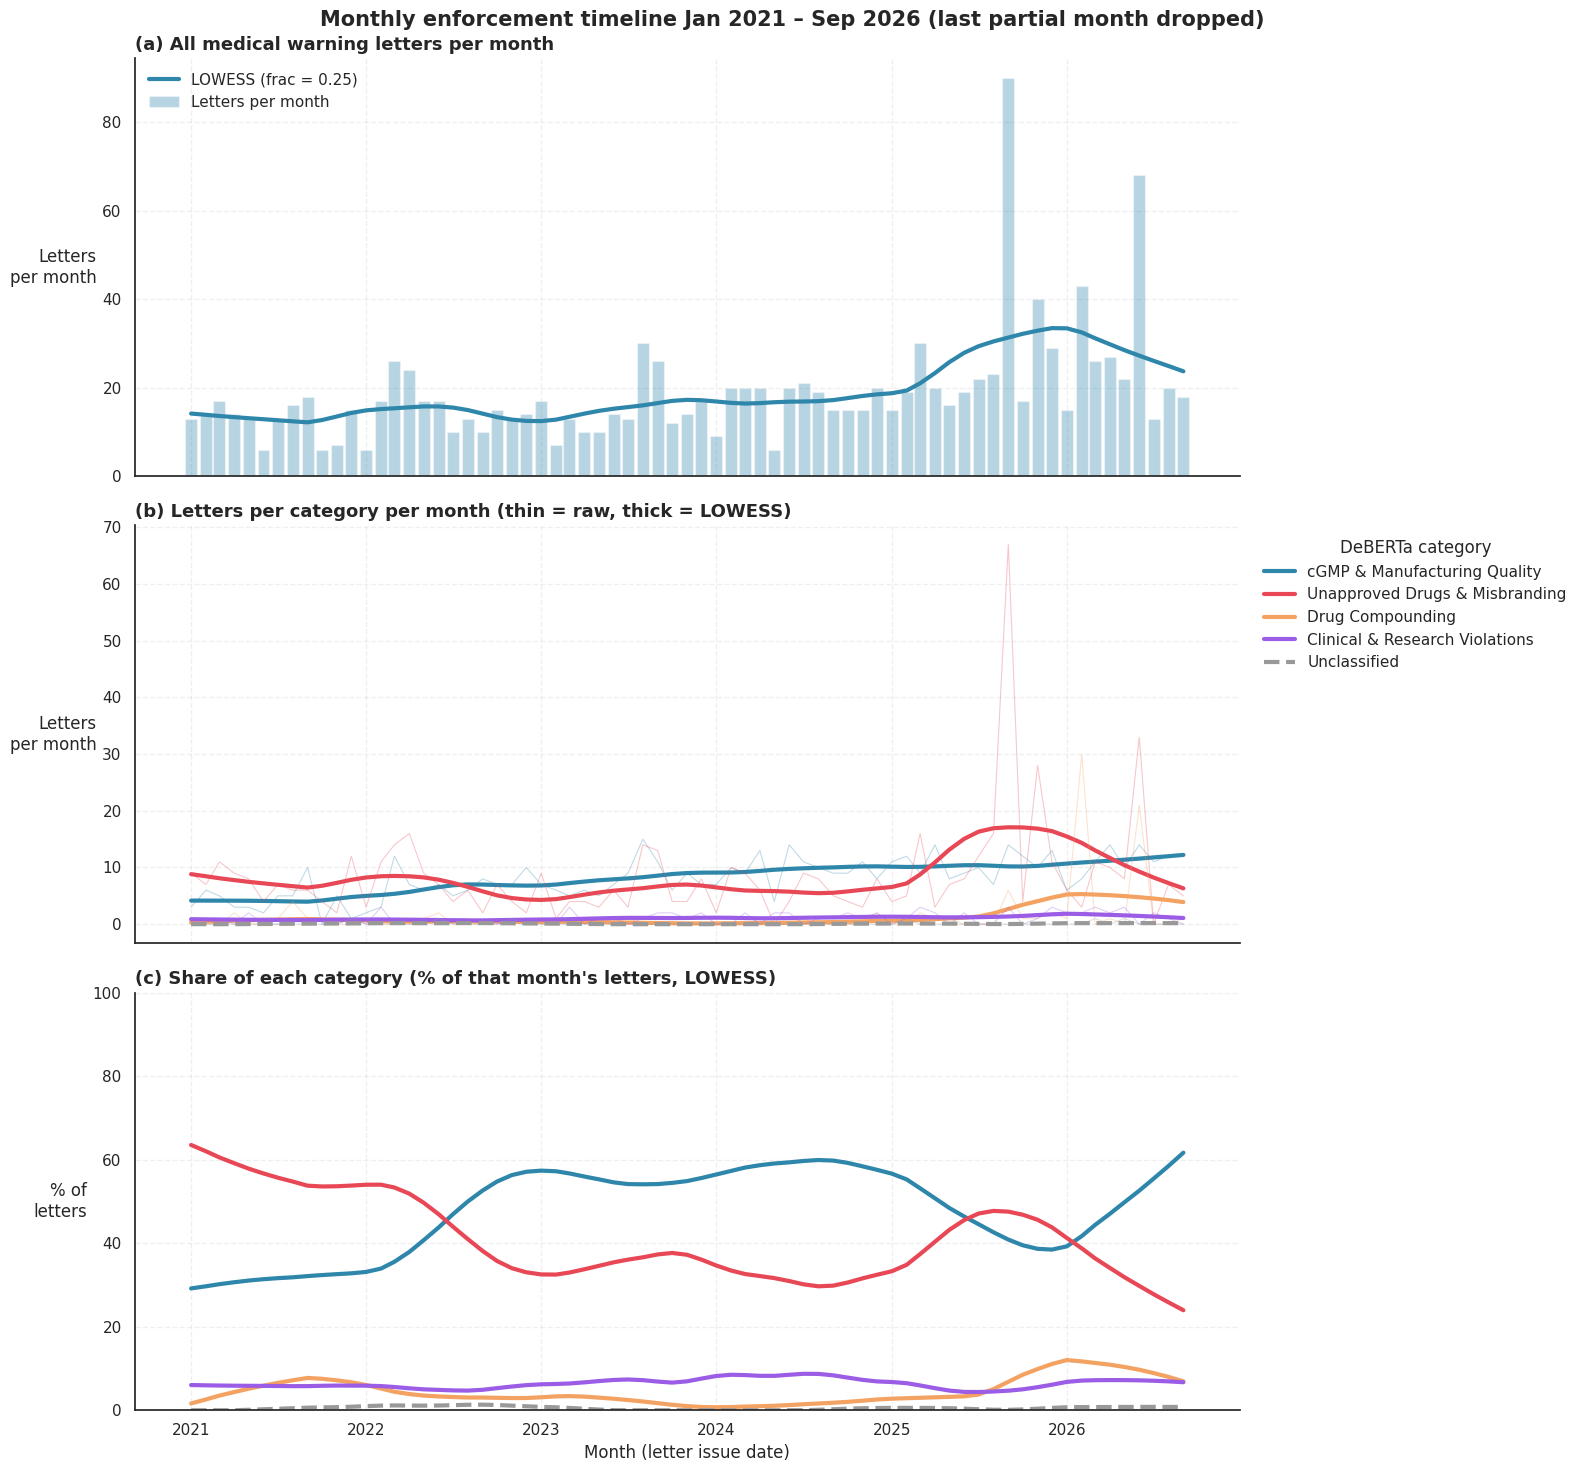

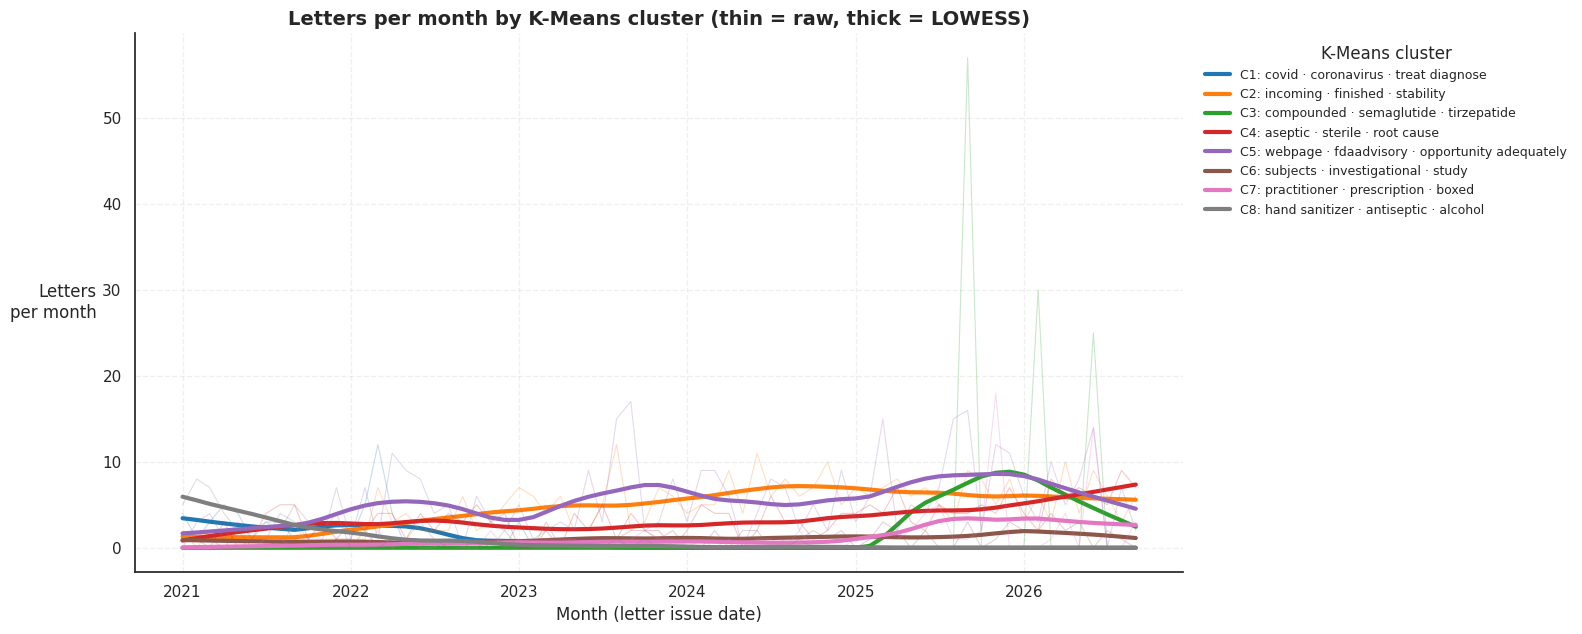

First 12 months = Jan 2021–Dec 2021 | last 12 months = Oct 2025–Sep 2026
pattern: ↑/↓ = count changed by more than 20% / share changed by more than 3 percentage points; → = roughly flat


,letters/month first 12,letters/month last 12,count change %,peak month,share % first 12,share % last 12,share change (pp),pattern
series,,,,,,,,
Total,12.7,28.2,122,Sep 2025 (90),NaN,NaN,NaN,NaN
cGMP & Manufacturing Quality,4.0,11.1,177,Aug 2023 (15),31.4,47.5,16.2,count ↑ · share ↑
Unapproved Drugs & Misbranding,7.1,10.5,48,Sep 2025 (67),56.4,33.8,-22.6,count ↑ · share ↓
Drug Compounding,0.8,4.8,544,Feb 2026 (30),5.8,11.0,5.2,count ↑ · share ↑
Clinical & Research Violations,0.8,1.6,111,Feb 2022 (3),5.9,7.0,1.0,count ↑ · share →
Unclassified,0.1,0.2,100,Dec 2021 (1),0.6,0.7,0.1,count ↑ · share →


💾 Saved monthly_counts.csv, monthly_share.csv, monthly_by_cluster.csv and 2 PNG figures to data


In [148]:
LOWESS_FRAC = 0.25
MONTHLY_COUNTS_OUT  = DATA_DIR / "monthly_counts.csv"
MONTHLY_SHARE_OUT   = DATA_DIR / "monthly_share.csv"
MONTHLY_CLUSTER_OUT = DATA_DIR / "monthly_by_cluster.csv"


def smooth(y, frac=LOWESS_FRAC):
    y = np.asarray(y, dtype=float)
    x = np.arange(len(y))
    ok = ~np.isnan(y)
    fit = lowess(y[ok], x[ok], frac=frac, it=0, return_sorted=False)
    return np.clip(np.interp(x, x[ok], fit), 0, None)


letters["month"] = letters["date"].dt.to_period("M").dt.to_timestamp()
last_full = LAST_DATE.to_period("M") - (0 if LAST_DATE.is_month_end else 1)
months = pd.period_range(f"{YEAR_MIN}-01", last_full, freq="M").to_timestamp()
in_window = letters["month"].between(months[0], months[-1])
cat_order = topic_list + [UNCLASSIFIED]
km_label = letters["kmeans_cluster"].map(lambda c: kmeans_names[c - 1])

monthly_counts = (pd.crosstab(letters.loc[in_window, "month"], letters.loc[in_window, "final_topic"])
                  .reindex(index=months, columns=cat_order, fill_value=0))
monthly_total = monthly_counts.sum(axis=1)
monthly_share = monthly_counts.div(monthly_total.replace(0, np.nan), axis=0) * 100
monthly_cluster = (pd.crosstab(letters.loc[in_window, "month"], km_label[in_window])
                   .reindex(index=months, columns=[kmeans_names[c] for c in range(K_KMEANS)], fill_value=0))

total_lowess   = pd.Series(smooth(monthly_total), index=months)
counts_lowess  = monthly_counts.apply(smooth)
share_lowess   = monthly_share.apply(smooth).clip(upper=100)
cluster_lowess = monthly_cluster.apply(smooth)

glp_cols = [c for c in monthly_cluster.columns
            if any(k in c.lower() for k in ("semaglutide", "tirzepatide", "glp"))]
print("LOWESS uses it=0 (no robustness iterations), frac =", LOWESS_FRAC)
smooth_check = pd.DataFrame({"max raw": monthly_cluster.max(), "max LOWESS": cluster_lowess.max().round(1)})
display(smooth_check)
if glp_cols:
    for col in glp_cols:
        print(f"GLP-1 cluster '{col}': max raw month = {monthly_cluster[col].max():.0f}, "
              f"max smoothed = {cluster_lowess[col].max():.1f}")
else:
    print("No K-Means cluster name contains semaglutide, tirzepatide or GLP-1.")

print(f"📅 {len(months)} full months: {months[0]:%b %Y} – {months[-1]:%b %Y} "
      f"(data ends {LAST_DATE:%d %b %Y}; {(~in_window).sum()} letters from the partial month dropped)")

# Figure 1: total, counts per category, share per category
sns.set_theme(style="white")
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(16, 15), sharex=True)
a1.bar(months, monthly_total, width=25, color="#2E86AB", alpha=0.35, label="Letters per month")
a1.plot(months, total_lowess, color="#2E86AB", linewidth=3, label=f"LOWESS (frac = {LOWESS_FRAC})")
a1.set_title("(a) All medical warning letters per month", fontsize=13, fontweight="bold", loc="left")
a1.set_ylabel("Letters\nper month", **HORIZONTAL_YLABEL)
a1.legend(frameon=False, loc="upper left")
for col in cat_order:
    style = dict(color=TOPIC_COLORS[col], linestyle="--" if col == UNCLASSIFIED else "-")
    a2.plot(months, monthly_counts[col], linewidth=0.8, alpha=0.3, color=style["color"])
    a2.plot(months, counts_lowess[col], linewidth=3, label=DISPLAY[col], **style)
    a3.plot(months, share_lowess[col], linewidth=3, label=DISPLAY[col], **style)
a2.set_title("(b) Letters per category per month (thin = raw, thick = LOWESS)", fontsize=13, fontweight="bold", loc="left")
a2.set_ylabel("Letters\nper month", **HORIZONTAL_YLABEL)
a3.set_title("(c) Share of each category (% of that month's letters, LOWESS)", fontsize=13, fontweight="bold", loc="left")
a3.set_ylabel("% of\nletters", **HORIZONTAL_YLABEL); a3.set_ylim(0, 100)
a3.set_xlabel("Month (letter issue date)")
a2.legend(title="DeBERTa category", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
for a in (a1, a2, a3):
    a.grid(True, linestyle="--", alpha=0.3); sns.despine(ax=a)
fig.suptitle(f"Monthly enforcement timeline {months[0]:%b %Y} – {months[-1]:%b %Y} (last partial month dropped)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(DATA_DIR / "fda_monthly_trends_lowess.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 2: K-Means clusters
fig, ax = plt.subplots(figsize=(16, 6.5))
for c, name in enumerate(monthly_cluster.columns):
    ax.plot(months, monthly_cluster[name], color=km_colors[c], linewidth=0.8, alpha=0.25)
    ax.plot(months, cluster_lowess[name], color=km_colors[c], linewidth=3, label=name)
ax.set_title("Letters per month by K-Means cluster (thin = raw, thick = LOWESS)", fontsize=14, fontweight="bold")
ax.set_xlabel("Month (letter issue date)"); ax.set_ylabel("Letters\nper month", **HORIZONTAL_YLABEL)
ax.legend(title="K-Means cluster", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=9)
ax.grid(True, linestyle="--", alpha=0.3); sns.despine()
plt.tight_layout()
plt.savefig(DATA_DIR / "fda_monthly_by_cluster_lowess.png", dpi=300, bbox_inches="tight")
plt.show()

# Tables
monthly_counts_table = pd.concat(
    [monthly_total.rename("Total"), total_lowess.round(2).rename("lowess: Total"),
     monthly_counts.rename(columns=DISPLAY),
     counts_lowess.round(2).rename(columns=lambda c: f"lowess: {DISPLAY[c]}")], axis=1).rename_axis("month")
monthly_share_table = pd.concat(
    [monthly_share.round(2).rename(columns=DISPLAY),
     share_lowess.round(2).rename(columns=lambda c: f"lowess: {DISPLAY[c]}")], axis=1).rename_axis("month")
monthly_cluster_table = pd.concat(
    [monthly_cluster, cluster_lowess.round(2).rename(columns=lambda c: f"lowess: {c}")], axis=1).rename_axis("month")
monthly_counts_table.to_csv(MONTHLY_COUNTS_OUT)
monthly_share_table.to_csv(MONTHLY_SHARE_OUT)
monthly_cluster_table.to_csv(MONTHLY_CLUSTER_OUT)


def arrow(change, flat):
    return "↑" if change > flat else "↓" if change < -flat else "→"


summary = []
for col in ["Total"] + cat_order:
    cnt = monthly_total if col == "Total" else monthly_counts[col]
    c0, c1 = cnt.iloc[:12].mean(), cnt.iloc[-12:].mean()
    row = {"series": DISPLAY.get(col, col),
           "letters/month first 12": round(c0, 1), "letters/month last 12": round(c1, 1),
           "count change %": round((c1 / c0 - 1) * 100) if c0 else np.nan}
    if col != "Total":
        s0, s1 = monthly_share[col].iloc[:12].mean(), monthly_share[col].iloc[-12:].mean()
        row.update({"share % first 12": round(s0, 1), "share % last 12": round(s1, 1),
                    "share change (pp)": round(s1 - s0, 1),
                    "pattern": f"count {arrow(c1 / c0 - 1 if c0 else 0, 0.2)} · share {arrow(s1 - s0, 3)}"})
    row["peak month"] = f"{cnt.idxmax():%b %Y} ({cnt.max()})"
    summary.append(row)
monthly_summary = pd.DataFrame(summary).set_index("series")
print(f"First 12 months = {months[0]:%b %Y}–{months[11]:%b %Y} | last 12 months = {months[-12]:%b %Y}–{months[-1]:%b %Y}")
print("pattern: ↑/↓ = count changed by more than 20% / share changed by more than 3 percentage points; → = roughly flat")
display(monthly_summary)
print(f"💾 Saved {MONTHLY_COUNTS_OUT.name}, {MONTHLY_SHARE_OUT.name}, {MONTHLY_CLUSTER_OUT.name} and 2 PNG figures to {DATA_DIR}")

### 8.6 קטגוריות DeBERTa מול הקבוצות הסמנטיות
בגרסה הקודמת הגרף טען שהקטגוריות של DeBERTa הן "Cluster 1/2/3" בלי שום בדיקה. כאן בודקים את זה באמת.

In [149]:
display(pd.crosstab(letters["semantic_cluster"].map(lambda c: sem_names[c - 1]),
                    letters["final_topic"].map(DISPLAY),
                    rownames=["Semantic cluster"], colnames=["DeBERTa"]))

DeBERTa,Clinical & Research Violations,Drug Compounding,Unapproved Drugs & Misbranding,Unclassified,cGMP & Manufacturing Quality
Semantic cluster,,,,,
C1: semaglutide · claims · advise,0,52,449,0,2
C2: consultant · guidance · contamination,76,38,139,6,570


## 8.7 BERTopic – מידול נושאים
BERTopic היא שיטה מבוססת Hugging Face / sentence-transformers: היא מקטינה את ה-embeddings ב-**UMAP**, מקבצת אותם ב-**HDBSCAN** (שמוצא לבד את מספר הנושאים ומשאיר מכתבים "חריגים" בנושא `-1`), ומתארת כל נושא במילים בעזרת **c-TF-IDF**.

* כדי שההשוואה לסעיף 6 תהיה ישירה, המודל משתמש **באותם embeddings של מכתב שלם** (`embeddings`, ממוצע של קטעי SBERT) ובאותו מודל (`sbert_model`) – לא מחשבים embeddings חדשים.
* `UMAP` עם `random_state=RANDOM_STATE` כדי שהתוצאה תהיה זהה בכל הרצה. `MIN_CLUSTER_SIZE` (ברירת מחדל 15) הוא הגודל המינימלי של נושא.
* **אוצר המילים** זהה לחלק של TF-IDF: אותן stop words, מילים של 4 אותיות ומעלה, מילים בודדות וצמדים, `min_df=5`, `max_df=0.6`. **חשוב:** BERTopic מאמן את ה-`CountVectorizer` על מסמך אחד מאוחד **לכל נושא**, ולכן אם מעבירים לו `min_df=5` ישירות, הוא נספר במספר **נושאים** ולא במספר **מכתבים**, ומילים ייחודיות לנושא אחד (למשל `semaglutide`) נמחקות. לכן אוצר המילים נבנה קודם על המכתבים עצמם, ורק אז מועבר ל-BERTopic כאוצר מילים קבוע.
* `REDUCE_OUTLIERS = True` משייך את המכתבים החריגים לנושא הקרוב ביותר לפי ה-embedding (`reduce_outliers(strategy="embeddings")`), ואז מילות המפתח של הנושאים מחושבות מחדש. התא מדפיס כמה חריגים היו לפני השיוך.

In [150]:
MIN_CLUSTER_SIZE = 15
REDUCE_OUTLIERS  = True

bt_docs = list(clean_texts)
bt_vocab = CountVectorizer(stop_words=list(base_stop_words), token_pattern=r'\b[a-zA-Z]{4,}\b',
                           ngram_range=(1, 2), min_df=5, max_df=0.6).fit(bt_docs).vocabulary_
bt_vectorizer = CountVectorizer(stop_words=list(base_stop_words), token_pattern=r'\b[a-zA-Z]{4,}\b',
                                ngram_range=(1, 2), vocabulary=bt_vocab)

topic_model = BERTopic(
    embedding_model=sbert_model,
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=RANDOM_STATE),
    hdbscan_model=HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, metric="euclidean",
                          cluster_selection_method="eom", prediction_data=True),
    vectorizer_model=bt_vectorizer,
    top_n_words=20,
)
bt_topics = np.asarray(topic_model.fit_transform(bt_docs, embeddings=embeddings)[0])
n_outliers = int((bt_topics == -1).sum())
print(f"🧩 BERTopic found {len(set(bt_topics) - {-1})} topics | outliers (topic -1): "
      f"{n_outliers} letters ({n_outliers / len(bt_topics):.0%})")

if REDUCE_OUTLIERS and n_outliers:
    bt_topics = np.asarray(topic_model.reduce_outliers(bt_docs, bt_topics, strategy="embeddings",
                                                       embeddings=embeddings))
    topic_model.update_topics(bt_docs, topics=bt_topics.tolist(), top_n_words=20, vectorizer_model=bt_vectorizer)
    print(f"   After reassigning outliers to the nearest topic: {(bt_topics == -1).sum()} outliers left")


def bt_keywords(t, n):
    return dedupe_terms([w for w, _ in topic_model.get_topic(t)], n)


bt_names = {t: "T-1: outliers" if t == -1 else f"T{t}: " + " · ".join(bt_keywords(t, 3))
            for t in sorted(set(bt_topics))}
topic_model.set_topic_labels(bt_names)
letters["bertopic"] = bt_topics
letters["bertopic_name"] = letters["bertopic"].map(bt_names)

2026-10-28 13:50:29,684 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


🧩 BERTopic found 30 topics | outliers (topic -1): 310 letters (23%)
   After reassigning outliers to the nearest topic: 0 outliers left


### 8.7.1 קבוצות מילות מפתח ועץ הנושאים
הבוחן ביקש לראות את **קבוצות מילות המפתח**. הטבלה מציגה לכל נושא את הגודל שלו ואת 8 מילות המפתח המובילות (אחרי הסרת כפילויות כמו `compounding` / `compounding pharmacy`, עם אותה פונקציה `dedupe_terms` מסעיף 2.4).

אחר כך נבנה **עץ היררכי של הנושאים** (`hierarchical_topics` + `get_topic_tree`): נושאים עם c-TF-IDF דומה מתאחדים שלב אחר שלב, וכך רואים איך קבוצות מילים קטנות מתאחדות לנושאים רחבים יותר (למשל כמה נושאי cGMP שמתאחדים לענף אחד של ייצור).

In [151]:
bt_table = pd.DataFrame([{"topic": t, "name": bt_names[t], "letters": int((bt_topics == t).sum()),
                          "top 8 keywords": ", ".join(bt_keywords(t, 8))}
                         for t in sorted(set(bt_topics))]).sort_values("letters", ascending=False)
with pd.option_context("display.max_colwidth", None):
    display(bt_table.set_index("topic"))

n_real_topics = int((bt_table["topic"] >= 0).sum())
hier_topics = None
if n_real_topics >= 3:
    hier_topics = topic_model.hierarchical_topics(bt_docs)
    print("\n🌳 Topic tree (topics with similar keywords merge into broader themes):\n")
    print(topic_model.get_topic_tree(hier_topics))
else:
    print("Fewer than 3 topics – no hierarchy to build.")

,name,letters,top 8 keywords
topic,,,
13,T13: stability · ongoing · finished,98,"stability, ongoing, finished, batches, detailed, performance, release, microbiological"
4,T4: water · cleaning · glycol,89,"water, cleaning, glycol, incoming, glycerin, ongoing, contamination, microbiological"
0,T0: outsourcing · sterile · compounded,79,"outsourcing, sterile, compounded, exemptions, compounding, qualify, aseptic, produced"
1,T1: study · subjects · investigational,78,"study, subjects, investigational, investigation, future, consent, form, enrolled"
20,T20: energy · webpage · genital,63,"energy, webpage, genital, supplement, male, public, herpes, body"
6,T6: aseptic · contamination · processing,62,"aseptic, contamination, processing, sterile, design, sterility, independent, filling"
11,T11: semaglutide · weight · zepbound,56,"semaglutide, weight, zepbound, patients, promotional, video, diabetes, peptide"
2,T2: biological · cord · tissue,53,"biological, cord, tissue, umbilical, biologics, amniotic, derived, processing"
3,T3: hand · sanitizer · alcohol,50,"hand, sanitizer, alcohol, antiseptic, methanol, ethanol, consumer, proposed"


100%|██████████| 29/29 [00:00<00:00, 180.44it/s]



🌳 Topic tree (topics with similar keywords merge into broader themes):

.
├─contamination_cleaning_stability_practices_ongoing
│    ├─stability_water_incoming_finished_ongoing
│    │    ├─■──relief_external_stability_final_monograph ── Topic: 18
│    │    └─stability_water_finished_incoming_ongoing
│    │         ├─water_stability_ongoing_incoming_cleaning
│    │         │    ├─■──glycol_glycerin_high_incoming_guidance document ── Topic: 26
│    │         │    └─water_stability_ongoing_cleaning_incoming
│    │         │         ├─■──water_cleaning_glycol_incoming_glycerin ── Topic: 4
│    │         │         └─■──stability_ongoing_finished_batches_detailed ── Topic: 13
│    │         └─talc_stability_manufacturer_provided_manufactured
│    │              ├─■──manufactured_dietary_listing_manufacturer_import ── Topic: 24
│    │              └─■──talc_stability_asbestos_provided_request ── Topic: 29
│    └─aseptic_contamination_integrity_deviations_cleaning
│         ├─deviations_integr

### 8.7.1b שתי רמות תצוגה, בלי לאחד נושאים
הנושאים הדקים נשארים כמו שהם. חלק מהכפילויות הן הבחנות אמיתיות, למשל מכתבי ג'ל חיטוי שיובאו מול מכתבי ייצור, או מכירת GLP-1 באינטרנט מול טענות שווא. מה שמשתנה הוא רק התצוגה.

* **נושאים רחבים:** העץ שכבר נבנה ב-`hierarchical_topics` נחתך לכ-9 ענפים. לכל ענף: מספר, שם קריא משלוש מילות המפתח של הענף המאוחד, מספר המכתבים, והנושאים הדקים שבתוכו. השיוך נשמר ב-`letters["bertopic_theme"]`. הנושאים עצמם לא מאוחדים במודל.
* **טבלת הסיכום של הנושאים הדקים:** גודל, 8 מילות מפתח, נושא ה-FDA הנפוץ ביותר והאחוז שלו, השנה הראשונה, השנה האחרונה, והשנה עם הכי הרבה מכתבים.

In [152]:
N_THEMES = 9
fine_ids = sorted(t for t in set(bt_topics.tolist()) if t >= 0)
n_leaves = len(fine_ids)
target = 9 if n_leaves > 10 else n_leaves

parent = {t: t for t in fine_ids}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

n_groups = n_leaves
if hier_topics is not None:
    for _, row in hier_topics.sort_values("Distance").iterrows():
        if n_groups <= target:
            break
        members = [int(t) for t in row["Topics"]]
        root = find(members[0])
        for t in members[1:]:
            rt = find(t)
            if rt != root:
                parent[rt] = root
                n_groups -= 1
    cover_name = {frozenset(int(t) for t in row.Topics): row.Parent_Name
                  for row in hier_topics.itertuples(index=False)}
else:
    cover_name = {}

groups = {}
for t in fine_ids:
    groups.setdefault(find(t), []).append(t)
if -1 in set(bt_topics.tolist()):
    groups.setdefault("outliers", [-1])

ordered = sorted(groups.items(), key=lambda kv: -int(np.isin(bt_topics, kv[1]).sum()))
theme_of = {}
theme_rows = []
for i, (root, members) in enumerate(ordered, start=1):
    real = [t for t in members if t >= 0]
    if real and frozenset(real) in cover_name:
        raw_words = [w for w in str(cover_name[frozenset(real)]).split("_") if w]
        words = dedupe_terms(raw_words, 3) or raw_words[:3]
    elif real:
        words = bt_keywords(real[0], 3)
    else:
        words = ["outliers"]
    name = f"G{i}: " + " · ".join(words)
    for t in members:
        theme_of[t] = name
    fine = ", ".join(bt_names[t] for t in sorted(real, key=lambda t: -int((bt_topics == t).sum())))
    theme_rows.append({"theme": i, "name": name, "letters": int(np.isin(bt_topics, members).sum()),
                       "fine topics": fine or "outliers"})

letters["bertopic_theme"] = letters["bertopic"].map(theme_of)
theme_table = pd.DataFrame(theme_rows)
print(f"{n_leaves} fine topics kept (not merged) | {theme_table['theme'].nunique()} broad themes")
with pd.option_context("display.max_colwidth", None):
    display(theme_table.set_index("theme"))

summary_rows = []
for t in sorted(set(bt_topics.tolist())):
    mask = letters["bertopic"] == t
    subj = letters.loc[mask, "subject"].fillna("(no subject)")
    share = subj.value_counts(normalize=True)
    yrs = letters.loc[mask, "year"]
    summary_rows.append({
        "topic": int(t),
        "name": bt_names[t],
        "letters": int(mask.sum()),
        "top 8 keywords": ", ".join(bt_keywords(t, 8)) if t >= 0 else "",
        "top FDA subject": share.index[0],
        "subject %": round(float(share.iloc[0]) * 100),
        "first year": int(yrs.min()),
        "last year": int(yrs.max()),
        "peak year": int(yrs.value_counts().idxmax()),
        "theme": theme_of[t],
    })
bt_table = pd.DataFrame(summary_rows).sort_values("letters", ascending=False)
print("Fine topics (all of them; duplicates are kept):")
with pd.option_context("display.max_colwidth", 80):
    display(bt_table.set_index("topic"))


30 fine topics kept (not merged) | 9 broad themes


,name,letters,fine topics
theme,,,
1,G1: contamination · cleaning · stability,480,"T13: stability · ongoing · finished, T4: water · cleaning · glycol, T6: aseptic · contamination · processing, T14: integrity · investigation · root, T12: deviations · cleaning · apis, T18: relief · external · stability, T24: manufactured · dietary · listing, T29: talc · stability · asbestos, T26: glycol · glycerin · high"
2,G2: skin · drops · cream,192,"T20: energy · webpage · genital, T11: semaglutide · weight · zepbound, T8: drops · eyes · relief, T23: numbing · skin · cream"
3,G3: study · subjects · investigational,157,"T0: outsourcing · sterile · compounded, T1: study · subjects · investigational"
4,G4: compounded · false · semaglutide,123,"T10: compounded · false · semaglutide, T16: tirzepatide · compounded · semaglutide, T17: compounded · false · tirzepatide, T28: semaglutide · compounded · false"
5,G5: hand · sanitizer · alcohol,90,"T3: hand · sanitizer · alcohol, T7: hand · sanitizer · alcohol"
6,G6: prescription · consumers · ketamine,90,"T9: prescription · benzodiazepines · tramadol, T22: ketamine · ammonia · smelling, T19: toxin · botulinum · cervical dystonia"
7,G7: covid · coronavirus · disease,85,"T5: covid · delta · coronavirus, T15: covid · antiseptic · disease"
8,G8: donor · tissue · biological,73,"T2: biological · cord · tissue, T25: donor · donors · semen"
9,G9: listing · registration · file,42,"T21: request · registered · respond, T27: listing · registration · file"


Fine topics (all of them; duplicates are kept):


,name,letters,top 8 keywords,top FDA subject,subject %,first year,last year,peak year,theme
topic,,,,,,,,,
13,T13: stability · ongoing · finished,98,"stability, ongoing, finished, batches, detailed, performance, release, micro...",CGMP/Finished Pharmaceuticals/Adulterated,85,2021,2026,2025,G1: contamination · cleaning · stability
4,T4: water · cleaning · glycol,89,"water, cleaning, glycol, incoming, glycerin, ongoing, contamination, microbi...",CGMP/Finished Pharmaceuticals/Adulterated,83,2021,2026,2024,G1: contamination · cleaning · stability
0,T0: outsourcing · sterile · compounded,79,"outsourcing, sterile, compounded, exemptions, compounding, qualify, aseptic,...",Compounding Pharmacy/Adulterated Drug Products,75,2021,2026,2025,G3: study · subjects · investigational
1,T1: study · subjects · investigational,78,"study, subjects, investigational, investigation, future, consent, form, enro...",Clinical Investigator,44,2021,2026,2026,G3: study · subjects · investigational
20,T20: energy · webpage · genital,63,"energy, webpage, genital, supplement, male, public, herpes, body",Unapproved New Drugs/Misbranded,54,2021,2026,2026,G2: skin · drops · cream
6,T6: aseptic · contamination · processing,62,"aseptic, contamination, processing, sterile, design, sterility, independent,...",CGMP/Finished Pharmaceuticals/Adulterated,85,2021,2026,2026,G1: contamination · cleaning · stability
11,T11: semaglutide · weight · zepbound,56,"semaglutide, weight, zepbound, patients, promotional, video, diabetes, peptide",Unapproved New Drugs/Misbranded,32,2021,2026,2025,G2: skin · drops · cream
2,T2: biological · cord · tissue,53,"biological, cord, tissue, umbilical, biologics, amniotic, derived, processing","Deviations/CFR/Regulations for Human Cells, Tissues & Cellular Products (HCT...",47,2021,2026,2024,G8: donor · tissue · biological
3,T3: hand · sanitizer · alcohol,50,"hand, sanitizer, alcohol, antiseptic, methanol, ethanol, consumer, proposed",Finished Pharmaceuticals/Unapproved New Drug/Misbranded/Adulterated,60,2021,2022,2021,G5: hand · sanitizer · alcohol


### 8.7.2 בדיקת תקפות: מה ה-FDA עצמו כתב על כל נושא
כמו בסעיפים 5.3 ו-7.1, משתמשים ב-`cluster_profile()` הקיימת: לכל נושא של BERTopic מודפסים שדות הנושא הרשמיים הנפוצים ביותר של ה-FDA ודוגמאות לחברות. אם נושא מקבל שם כמו `semaglutide · compounded · ...` ושדה הנושא של רוב המכתבים בו הוא Compounding / Unapproved, זה סימן שהנושא אמיתי.

In [153]:
cluster_profile(bt_topics, bt_names)


📁 T0: outsourcing · sterile · compounded  —  79 letters
   FDA subject lines:
       75%  Compounding Pharmacy/Adulterated Drug Products
       10%  Nonprescription/OTC
        8%  Unlawful Sale of Unapproved and Misbranded Drugs to United States Consumers Over the Inter
   Example companies: Advanced Nutriceuticals, LLC dba The Guyer Institute of Molecular Medicine; Age Management Institute Santa Barbara; Amazing Meds; American Specialty Pharmacy, Inc. dba ASP Cares

📁 T1: study · subjects · investigational  —  78 letters
   FDA subject lines:
       44%  Clinical Investigator
       10%  Clinical Investigator (Sponsor)
        6%  In Vivo Bioavailability-Bioequivalence Studies – Clinical
   Example companies: Adarsh Daswani, M.D.; Adnan Dahdul, MD; American Behavioral Research Institute, LLC; Americo F. Padilla, M.D.

📁 T2: biological · cord · tissue  —  53 letters
   FDA subject lines:
       47%  Deviations/CFR/Regulations for Human Cells, Tissues & Cellular Products (HCT/Ps)
    

### 8.7.3 הסכמה עם שאר השיטות
לכל נושא של BERTopic בודקים איזה אחוז מהמכתבים שלו נמצאים **באשכול הנפוץ ביותר שלהם** ב-K-Means, באשכול הסמנטי וגם בקטגוריית DeBERTa. 100% = כל מכתבי הנושא נמצאים באותו אשכול/קטגוריה. בסוף מודפס ממוצע משוקלל לפי גודל הנושא, וטבלה מלאה של BERTopic מול K-Means.

שימו לב: לשיטה הסמנטית יש רק מעט אשכולות, ולכן האחוז מולה גבוה כמעט באופן אוטומטי. ההשוואה מול K-Means ומול DeBERTa אינפורמטיבית יותר.

In [154]:
km_lab  = letters["kmeans_cluster"].map(lambda c: kmeans_names[c - 1])
sem_lab = letters["semantic_cluster"].map(lambda c: sem_names[c - 1])
deb_lab = letters["final_topic"].map(DISPLAY)

bt_agree = letters["bertopic_name"].value_counts().rename("letters").to_frame()
for label, other in [("K-Means", km_lab), ("Semantic", sem_lab), ("DeBERTa", deb_lab)]:
    ct = pd.crosstab(letters["bertopic_name"], other)
    bt_agree[f"top {label}"] = ct.idxmax(axis=1)
    bt_agree[f"% in top {label}"] = (ct.max(axis=1) / ct.sum(axis=1) * 100).round(0)
with pd.option_context("display.max_colwidth", 45):
    display(bt_agree)

for label in ["K-Means", "Semantic", "DeBERTa"]:
    w = (bt_agree[f"% in top {label}"] * bt_agree["letters"]).sum() / bt_agree["letters"].sum()
    print(f"Weighted share of BERTopic letters in their topic's most common {label:8s} group: {w:.0f}%")
print(f"Adjusted Rand index BERTopic vs K-Means: {adjusted_rand_score(letters['bertopic'], letters['kmeans_cluster']):.2f}")

display(pd.crosstab(letters["bertopic_name"], km_lab, rownames=["BERTopic"], colnames=["K-Means"]))

,letters,top K-Means,% in top K-Means,top Semantic,% in top Semantic,top DeBERTa,% in top DeBERTa
bertopic_name,,,,,,,
T13: stability · ongoing · finished,98,C2: incoming · finished · stability,85.0,C2: consultant · guidance · contamination,100.0,cGMP & Manufacturing Quality,100.0
T4: water · cleaning · glycol,89,C2: incoming · finished · stability,93.0,C2: consultant · guidance · contamination,100.0,cGMP & Manufacturing Quality,97.0
T0: outsourcing · sterile · compounded,79,C4: aseptic · sterile · root cause,80.0,C2: consultant · guidance · contamination,90.0,Drug Compounding,48.0
T1: study · subjects · investigational,78,C6: subjects · investigational · study,96.0,C2: consultant · guidance · contamination,100.0,Clinical & Research Violations,97.0
T20: energy · webpage · genital,63,C5: webpage · fdaadvisory · opportunity a...,100.0,C1: semaglutide · claims · advise,100.0,Unapproved Drugs & Misbranding,100.0
T6: aseptic · contamination · processing,62,C4: aseptic · sterile · root cause,98.0,C2: consultant · guidance · contamination,100.0,cGMP & Manufacturing Quality,100.0
T11: semaglutide · weight · zepbound,56,C5: webpage · fdaadvisory · opportunity a...,77.0,C1: semaglutide · claims · advise,100.0,Unapproved Drugs & Misbranding,100.0
T2: biological · cord · tissue,53,C5: webpage · fdaadvisory · opportunity a...,100.0,C2: consultant · guidance · contamination,100.0,Unapproved Drugs & Misbranding,68.0
T3: hand · sanitizer · alcohol,50,C8: hand sanitizer · antiseptic · alcohol,96.0,C2: consultant · guidance · contamination,100.0,Unapproved Drugs & Misbranding,80.0


Weighted share of BERTopic letters in their topic's most common K-Means  group: 87%
Weighted share of BERTopic letters in their topic's most common Semantic group: 99%
Weighted share of BERTopic letters in their topic's most common DeBERTa  group: 90%
Adjusted Rand index BERTopic vs K-Means: 0.22


K-Means,C1: covid · coronavirus · treat diagnose,C2: incoming · finished · stability,C3: compounded · semaglutide · tirzepatide,C4: aseptic · sterile · root cause,C5: webpage · fdaadvisory · opportunity adequately,C6: subjects · investigational · study,C7: practitioner · prescription · boxed,C8: hand sanitizer · antiseptic · alcohol
BERTopic,,,,,,,,
T0: outsourcing · sterile · compounded,0,0,5,63,11,0,0,0
T10: compounded · false · semaglutide,0,0,26,0,15,0,0,0
T11: semaglutide · weight · zepbound,0,0,0,0,43,0,13,0
T12: deviations · cleaning · apis,0,12,0,33,0,0,0,0
T13: stability · ongoing · finished,0,83,0,15,0,0,0,0
T14: integrity · investigation · root,0,3,0,43,0,0,0,0
T15: covid · antiseptic · disease,22,0,0,0,15,0,0,0
T16: tirzepatide · compounded · semaglutide,0,0,32,0,1,0,0,0
T17: compounded · false · tirzepatide,0,0,32,0,0,0,0,0


### 8.7.4 נושאים לאורך זמן (חודשי)
`topics_over_time` סופר לכל נושא כמה מכתבים היו בכל **חודש** (לפי `letters["month"]` מסעיף 8.5.3), ומחשב את מילות המפתח של הנושא באותו חודש. כך רואים גם מתי נושא היה פעיל וגם איך השפה שלו השתנתה. התוצאה נשמרת ל-CSV.

In [155]:
TOPICS_TIME_OUT = DATA_DIR / "bertopic_topics_over_time.csv"

topics_time = topic_model.topics_over_time(bt_docs, letters["month"].tolist(),
                                           global_tuning=True, evolution_tuning=True)
topics_time["Name"] = topics_time["Topic"].map(bt_names)
topics_time.to_csv(TOPICS_TIME_OUT, index=False)
print(f"💾 {topics_time['Timestamp'].nunique()} monthly bins × {topics_time['Topic'].nunique()} topics → {TOPICS_TIME_OUT}")

💾 70 monthly bins × 30 topics → data/bertopic_topics_over_time.csv


### 8.7.5 גרפים אינטראקטיביים (Plotly)
שלושה גרפים אינטראקטיביים של BERTopic, שמוצגים כאן וגם נשמרים כקבצי HTML (אפשר לפתוח אותם בדפדפן ולצרף לעבודה):
1. **מילות מפתח לכל נושא** (barchart של ציוני c-TF-IDF).
2. **היררכיית הנושאים** – אותו עץ מ-8.7.1 כדנדרוגרמה.
3. **נושאים לאורך זמן** – 10 הנושאים הגדולים, לפי חודש.

In [156]:
fig_bar = topic_model.visualize_barchart(top_n_topics=n_real_topics, n_words=8, custom_labels=True,
                                        width=300, height=280, title="BERTopic – top keywords per topic")
fig_bar.write_html(DATA_DIR / "bertopic_keywords_barchart.html")
fig_bar.show()

if hier_topics is not None:
    fig_hier = topic_model.visualize_hierarchy(hierarchical_topics=hier_topics, custom_labels=True,
                                               title="<b>BERTopic – topic hierarchy</b>")
    fig_hier.write_html(DATA_DIR / "bertopic_hierarchy.html")
    fig_hier.show()

fig_time = topic_model.visualize_topics_over_time(topics_time, top_n_topics=10, custom_labels=True,
                                                  title="<b>BERTopic – top 10 topics over time (monthly)</b>")
fig_time.write_html(DATA_DIR / "bertopic_topics_over_time.html")
fig_time.show()
print(f"💾 Saved interactive HTML figures to {DATA_DIR}")

💾 Saved interactive HTML figures to data


### 8.7.6 גרפים סטטיים לעבודה: לפי נושא רחב ולפי הנושאים הדקים הגדולים
הגרף הקודם ערם את כל הנושאים הדקים בעמודה אחת, עם צבעים שחוזרים על עצמם, ואי אפשר היה לקרוא אותו. במקומו שני גרפים, שניהם PNG ב-300 dpi:

1. **לפי נושא רחב** (כ-9 צבעים שונים, `tab10`).
2. **12 הנושאים הדקים הגדולים**, וכל השאר בקבוצה אפורה אחת בשם Other. לכל נושא צבע משלו, בלי חזרות.


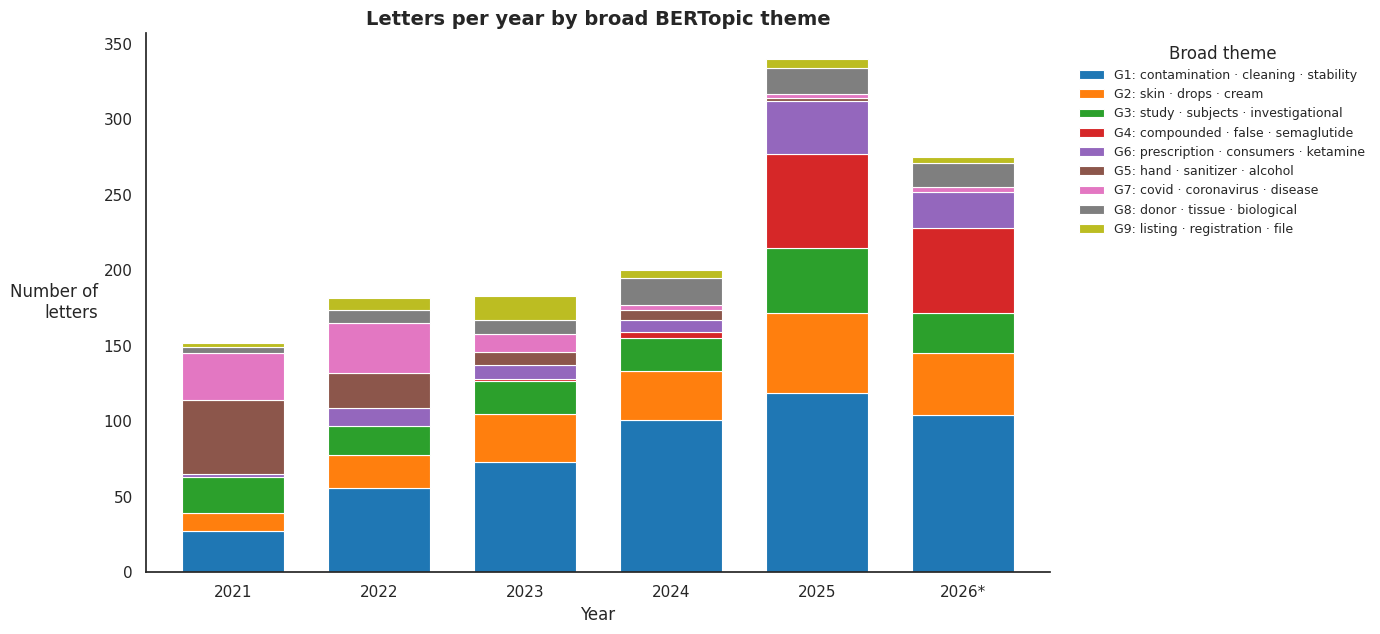

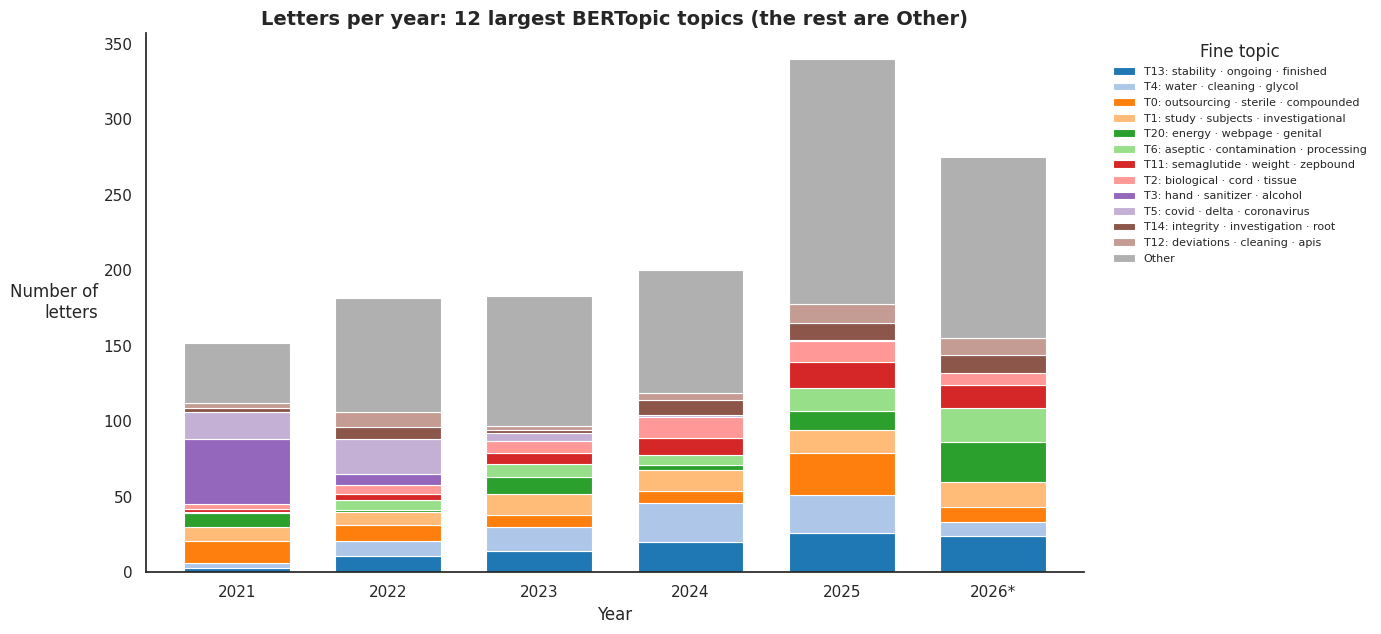

9 theme colors, 12 fine-topic colors, Other in grey


In [157]:
theme_order = letters["bertopic_theme"].value_counts().index.tolist()
year_theme = (pd.crosstab(letters["year"], letters["bertopic_theme"])
              .reindex(index=years, columns=theme_order, fill_value=0))
theme_colors = sns.color_palette("tab10", year_theme.shape[1])

ax = year_theme.plot(kind="bar", stacked=True, figsize=(14, 6.5), width=0.7, color=theme_colors,
                     edgecolor="white", linewidth=0.8)
ax.set_xticklabels(xt, rotation=0)
ax.set_title("Letters per year by broad BERTopic theme", fontsize=14, fontweight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("Number of\nletters", **HORIZONTAL_YLABEL)
ax.legend(title="Broad theme", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=9)
sns.despine(); plt.tight_layout()
plt.savefig(DATA_DIR / "fda_year_by_bertopic_theme.png", dpi=300, bbox_inches="tight")
plt.show()

N_TOP_FINE = 12
top_fine = letters["bertopic_name"].value_counts().head(N_TOP_FINE).index.tolist()
shown = letters["bertopic_name"].where(letters["bertopic_name"].isin(top_fine), "Other")
fine_order = [name for name in top_fine if name in set(shown)]
if (shown == "Other").any():
    fine_order.append("Other")
year_fine = pd.crosstab(letters["year"], shown).reindex(index=years, columns=fine_order, fill_value=0)
fine_colors = list(sns.color_palette("tab20", len(fine_order)))
if fine_order[-1] == "Other":
    fine_colors[-1] = (0.69, 0.69, 0.69)

ax = year_fine.plot(kind="bar", stacked=True, figsize=(14, 6.5), width=0.7, color=fine_colors,
                    edgecolor="white", linewidth=0.8)
ax.set_xticklabels(xt, rotation=0)
ax.set_title(f"Letters per year: {N_TOP_FINE} largest BERTopic topics (the rest are Other)", fontsize=14, fontweight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("Number of\nletters", **HORIZONTAL_YLABEL)
ax.legend(title="Fine topic", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=8)
sns.despine(); plt.tight_layout()
plt.savefig(DATA_DIR / "fda_year_by_bertopic.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"{year_theme.shape[1]} theme colors, {len(top_fine)} fine-topic colors, Other in grey")


## 8.8 תחזית עם Prophet
**Prophet** (של Meta) מפרק סדרת זמן למגמה + עונתיות שנתית, ומחזיר תחזית עם רווח סמך. כאן חוזים את הסדרות החודשיות מסעיף 8.5.3: סך המכתבים וכל קטגוריית DeBERTa (בלי Unclassified), ל-`HORIZON` = 6 חודשים קדימה.

* הגדרות: תדירות חודשית (`MS`), עונתיות שנתית פעילה, שבועית/יומית כבויות, רווח סמך של 80%. תחזיות שליליות נחתכות ל-0. רווח הסמך של **סכום** 6 החודשים מחושב מתוך הדגימות של Prophet (`predictive_samples`), ולא כסכום של הגבולות של כל חודש.
* **Backtest (בדיקה לאחור):** לכל סדרה מאמנים בלי 6 החודשים האחרונים, חוזים אותם ומחשבים **MAE** (טעות מוחלטת ממוצעת במכתבים לחודש). משווים לבסיס נאיבי: הממוצע של 6 החודשים שלפני תקופת הבדיקה. אם Prophet לא מנצח את הבסיס הנאיבי, אין סיבה לסמוך על התחזית שלו לסדרה הזו.
* אחר כך מאמנים מחדש על כל החודשים וחוזים 6 חודשים קדימה.

> ⚠️ **התחזית היא אינדיקציה בלבד.** יש רק כ-70 נקודות חודשיות, ובשנת 2025 יש **שבירה מבנית** (קפיצה חדה במכתבים על תרופות לא מאושרות / GLP-1 ו-Telehealth, ראו 8.5.1), שמודל מגמה + עונתיות לא יכול לצפות מראש. בנוסף, ה-FDA מפרסם מכתבים באיחור, ולכן החודשים האחרונים עשויים להיות חסרים ולמשוך את התחזית למטה. טבלת ה-backtest היא מה שמראה אם Prophet באמת עדיף על הבסיס הנאיבי.

In [158]:
HORIZON = 6
BACKTEST_MONTHS = 6
FORECAST_OUT = DATA_DIR / "prophet_forecast.csv"
BACKTEST_OUT = DATA_DIR / "prophet_backtest.csv"

fc_series = {"Total": monthly_total, **{DISPLAY[t]: monthly_counts[t] for t in topic_list}}
fc_colors = {"Total": "#333333", **{DISPLAY[t]: TOPIC_COLORS[t] for t in topic_list}}
last_actual = months[-1]


def fit_prophet(y):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, interval_width=0.8)
    return m.fit(pd.DataFrame({"ds": y.index, "y": y.to_numpy(float)}), seed=RANDOM_STATE)


def prophet_predict(m, periods):
    future = m.make_future_dataframe(periods=periods, freq="MS")
    np.random.seed(RANDOM_STATE)
    fc = m.predict(future)
    np.random.seed(RANDOM_STATE)
    samples = np.clip(m.predictive_samples(future)["yhat"], 0, None)
    fc[["yhat", "yhat_lower", "yhat_upper"]] = fc[["yhat", "yhat_lower", "yhat_upper"]].clip(lower=0)
    return fc, samples


backtest_rows, forecasts = [], {}
for name, y in tqdm(fc_series.items(), desc="Prophet"):
    train, test = y.iloc[:-BACKTEST_MONTHS], y.iloc[-BACKTEST_MONTHS:]
    test_fc, _ = prophet_predict(fit_prophet(train), BACKTEST_MONTHS)
    mae_prophet = np.abs(test_fc["yhat"].iloc[-BACKTEST_MONTHS:].to_numpy() - test.to_numpy()).mean()
    mae_naive = np.abs(train.iloc[-BACKTEST_MONTHS:].mean() - test.to_numpy()).mean()

    fc, samples = prophet_predict(fit_prophet(y), HORIZON)
    fc["actual"] = fc["ds"].map(y)
    forecasts[name] = fc
    lo, hi = np.percentile(samples[-HORIZON:].sum(axis=0), [10, 90])
    backtest_rows.append({
        "series": name,
        "MAE Prophet": round(mae_prophet, 2),
        "MAE naive": round(mae_naive, 2),
        "Prophet better?": "yes" if mae_prophet < mae_naive else "no",
        f"actual sum last {BACKTEST_MONTHS} months": int(y.iloc[-BACKTEST_MONTHS:].sum()),
        f"forecast sum next {HORIZON} months": round(fc["yhat"].iloc[-HORIZON:].sum()),
        "80% interval of the sum": f"{lo:.0f}–{hi:.0f}",
    })

backtest = pd.DataFrame(backtest_rows)
forecast_table = pd.concat(
    [fc.assign(series=name, type=np.where(fc["ds"] > last_actual, "forecast", "fit"))
       [["series", "ds", "type", "actual", "yhat", "yhat_lower", "yhat_upper"]] for name, fc in forecasts.items()],
    ignore_index=True)
forecast_table[["yhat", "yhat_lower", "yhat_upper"]] = forecast_table[["yhat", "yhat_lower", "yhat_upper"]].round(2)
backtest.to_csv(BACKTEST_OUT, index=False)
forecast_table.to_csv(FORECAST_OUT, index=False)

print(f"Backtest: trained up to {months[-BACKTEST_MONTHS - 1]:%b %Y}, tested on "
      f"{months[-BACKTEST_MONTHS]:%b %Y}–{last_actual:%b %Y}. "
      f"Forecast: {last_actual + pd.DateOffset(months=1):%b %Y}–{last_actual + pd.DateOffset(months=HORIZON):%b %Y}.")
print(f"Naive baseline = mean of the {BACKTEST_MONTHS} months before the test period. MAE = letters per month.")
display(backtest.set_index("series"))
print(f"💾 Saved {BACKTEST_OUT.name} and {FORECAST_OUT.name}")

Prophet:   0%|          | 0/5 [00:00<?, ?it/s]

Backtest: trained up to Mar 2026, tested on Apr 2026–Sep 2026. Forecast: Oct 2026–Mar 2027.
Naive baseline = mean of the 6 months before the test period. MAE = letters per month.


,MAE Prophet,MAE naive,Prophet better?,actual sum last 6 months,forecast sum next 6 months,80% interval of the sum
series,,,,,,
Total,15.31,13.56,no,168,170,138–203
cGMP & Manufacturing Quality,1.69,2.17,yes,73,73,66–80
Unapproved Drugs & Misbranding,9.86,7.50,no,63,63,42–90
Drug Compounding,4.92,7.06,yes,23,22,15–36
Clinical & Research Violations,1.15,1.00,no,8,11,9–14


💾 Saved prophet_backtest.csv and prophet_forecast.csv


### 8.8.1 גרף התחזית
פאנל לכל סדרה: עמודות אפורות = מספר המכתבים בפועל, קו כחול = ההתאמה של Prophet לעבר, קו צבעוני עם נקודות = התחזית ל-6 החודשים הבאים, ורצועה = רווח סמך של 80%. הקו המקווקו מסמן את החודש המלא האחרון שיש לו נתונים.

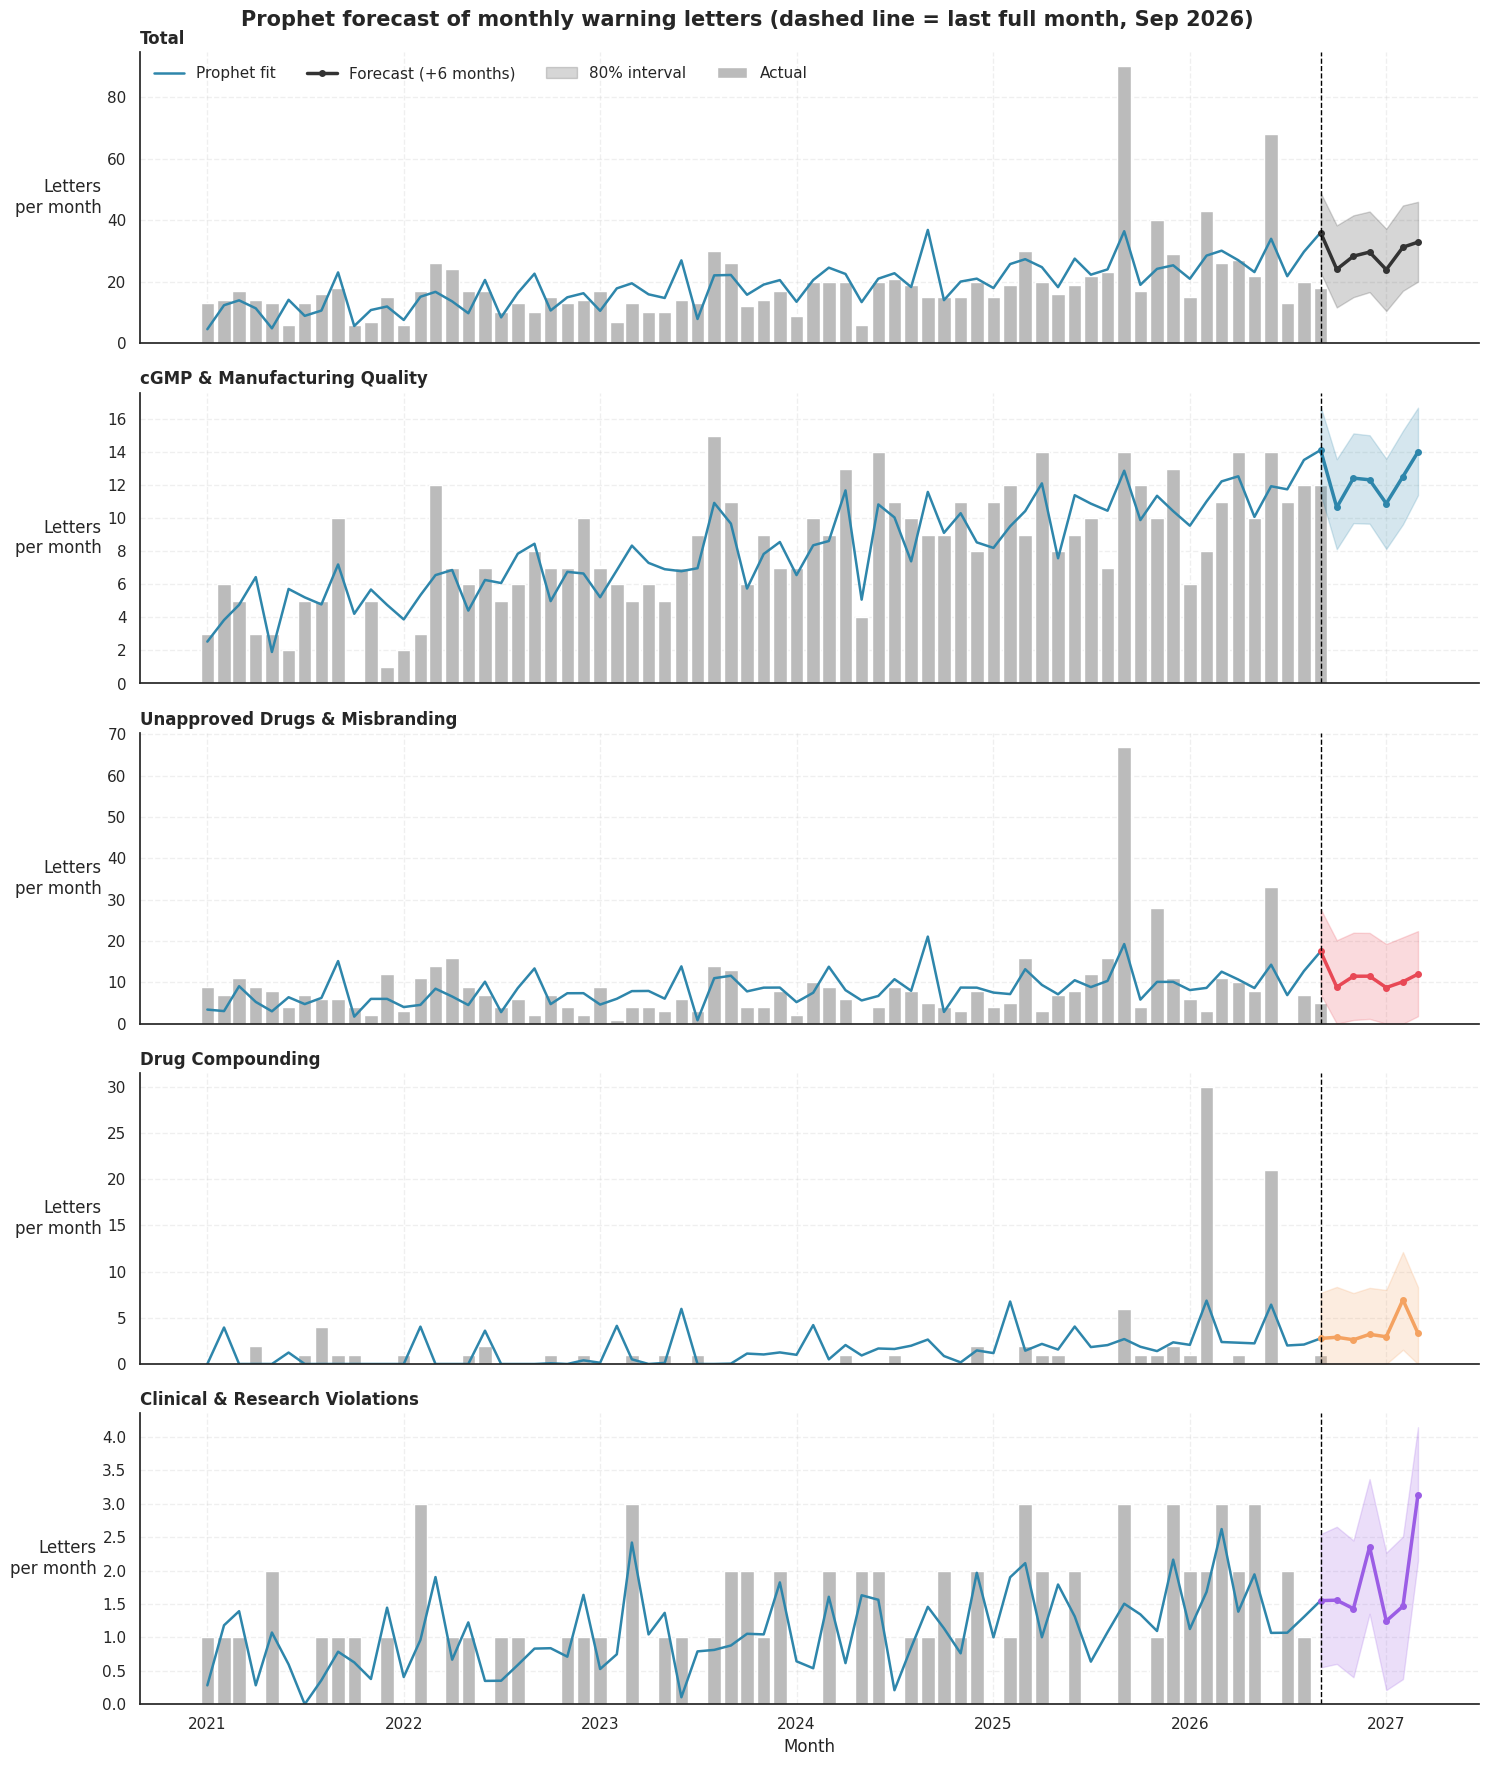

In [159]:
fig, axes = plt.subplots(len(forecasts), 1, figsize=(15, 3.6 * len(forecasts)), sharex=True)
for ax, (name, fc) in zip(axes, forecasts.items()):
    hist, fut = fc[fc["ds"] <= last_actual], fc[fc["ds"] >= last_actual]
    color = fc_colors[name]
    ax.bar(hist["ds"], hist["actual"], width=25, color="#BBBBBB", label="Actual")
    ax.plot(hist["ds"], hist["yhat"], color="#2E86AB", linewidth=1.8, label="Prophet fit")
    ax.plot(fut["ds"], fut["yhat"], color=color, linewidth=2.5, marker="o", markersize=4,
            label=f"Forecast (+{HORIZON} months)")
    ax.fill_between(fut["ds"], fut["yhat_lower"], fut["yhat_upper"], color=color, alpha=0.2, label="80% interval")
    ax.axvline(last_actual, color="black", linestyle="--", linewidth=1)
    ax.set_title(name, fontsize=12, fontweight="bold", loc="left")
    ax.set_ylabel("Letters\nper month", **HORIZONTAL_YLABEL)
    ax.set_ylim(bottom=0); ax.grid(True, linestyle="--", alpha=0.3); sns.despine(ax=ax)
axes[0].legend(frameon=False, loc="upper left", ncol=4)
axes[-1].set_xlabel("Month")
fig.suptitle(f"Prophet forecast of monthly warning letters (dashed line = last full month, {last_actual:%b %Y})",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(DATA_DIR / "fda_prophet_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. שמירת התוצאות והורדה למחשב
שומר טבלה אחת עם כל התוצאות לכל מכתב, ובמחשב של Colab גם מוריד אותה אוטומטית למחשב שלך. אם `SAVE_TO_DRIVE = True`, כל הקבצים כבר נמצאים ב-Google Drive בתיקייה `FDA_project`.

In [160]:
cols = ["url", "company", "date", "year", "office", "subject",
        "kmeans_cluster", "semantic_cluster", "final_topic", "reference_topic"]
results = letters[cols].copy()
results["kmeans_name"]   = results["kmeans_cluster"].map(lambda c: kmeans_names[c - 1])
results["semantic_name"] = results["semantic_cluster"].map(lambda c: sem_names[c - 1])
results.to_csv(RESULTS_OUT, index=False)
print(f"💾 Saved {len(results)} rows to {RESULTS_OUT}")

try:
    from google.colab import files
    for p in [RESULTS_OUT, OFFICES_OUT, DATA_DIR / "fda_yearly_enforcement_trends.png"]:
        files.download(str(p))
except ImportError:
    pass

💾 Saved 1332 rows to data/fda_letters_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 9.1 ייצוא נתונים לדשבורד
התא הזה שומר בתיקייה `dashboard_data/` (בתוך `DATA_DIR`) את כל מה שהדשבורד (`dashboard.py`) צריך, כדי שהדשבורד **לא יריץ אף מודל** ורק יקרא קבצים:
* `letters.csv` – שורה לכל מכתב: פרטים, קטגוריית DeBERTa, נושא הייחוס, אשכולות K-Means / סמנטי / BERTopic עם שמות, ציוני הנושאים, מספר הקטעים הרלוונטיים, הראיה, וקואורדינטות t-SNE ו-SVD.
* הסדרות החודשיות (8.5.3), התחזית וה-backtest (8.8), טבלת הנושאים ו-topics over time של BERTopic (8.7), פסקאות הראיה (8.3) והמילים הבולטות של כל אשכול (5.3, 7.1).
* `kpis.json` – המספרים לכרטיסים בעמוד הראשי (הסכמה בין השיטות, דיוק DeBERTa מול נושא ה-FDA) והצבעים של הקטגוריות.

**הרצת הדשבורד:** `pip install streamlit plotly pandas`, ואז מהתיקייה של המחברת: `streamlit run dashboard.py` (או `python3 -m streamlit run dashboard.py`).

In [161]:
DASH_DIR = DATA_DIR / "dashboard_data"
DASH_DIR.mkdir(parents=True, exist_ok=True)

dash = letters[["url", "company", "date", "month", "year", "office", "subject"]].copy()
dash["category"]         = letters["final_topic"].map(DISPLAY)
dash["reference_topic"]  = letters["reference_topic"].map(DISPLAY)
dash["kmeans_cluster"]   = letters["kmeans_cluster"]
dash["kmeans_name"]      = letters["kmeans_cluster"].map(lambda c: kmeans_names[c - 1])
dash["semantic_cluster"] = letters["semantic_cluster"]
dash["semantic_name"]    = letters["semantic_cluster"].map(lambda c: sem_names[c - 1])
dash["bertopic"]         = letters["bertopic"]
dash["bertopic_name"]    = letters["bertopic_name"]
dash["bertopic_theme"]   = letters["bertopic_theme"]
for col in SCORE_COLS.values():
    dash[col] = letters[col]
dash["relevant_chunks"] = letters["relevant_chunks"]
dash["evidence"]        = letters["evidence"]
dash["tsne_x"], dash["tsne_y"] = tsne_xy[:, 0], tsne_xy[:, 1]
dash["svd_x"],  dash["svd_y"]  = svd_xy[:, 0], svd_xy[:, 1]

terms_long = pd.DataFrame([
    {"method": method, "cluster": c + 1, "cluster_name": names[c], "rank": r + 1, "term": term, "score": round(score, 5)}
    for method, dist, names in [("K-Means", kmeans_dist, kmeans_names), ("Semantic", sem_dist, sem_names)]
    for c, df_t in dist.items()
    for r, (term, score) in enumerate(zip(df_t["term"], df_t["score"]))])

km_sem = pd.crosstab(letters["kmeans_cluster"], letters["semantic_cluster"])
ref = letters[letters["reference_topic"].notna()]
kpis = {
    "n_letters": int(len(letters)),
    "year_min": int(letters["year"].min()), "year_max": int(letters["year"].max()),
    "last_date": f"{LAST_DATE:%Y-%m-%d}",
    "partial_year": int(partial_year) if partial_year else None,
    "km_sem_agreement": float(km_sem.max(axis=1).sum() / km_sem.values.sum()),
    "km_sem_ari": float(adjusted_rand_score(letters["kmeans_cluster"], letters["semantic_cluster"])),
    "deberta_agreement": float((ref["final_topic"] == ref["reference_topic"]).mean()),
    "n_reference": int(len(ref)),
    "irrelevant_chunk_share": float((~relevant).mean()),
    "n_bertopic_topics": int(n_real_topics),
    "lowess_frac": LOWESS_FRAC, "horizon": HORIZON,
    "category_colors": {DISPLAY[k]: v for k, v in TOPIC_COLORS.items()},
}

exports = {
    "letters.csv":                   dash,
    "monthly_counts.csv":            monthly_counts_table.reset_index(),
    "monthly_share.csv":             monthly_share_table.reset_index(),
    "monthly_by_cluster.csv":        monthly_cluster_table.reset_index(),
    "prophet_forecast.csv":          forecast_table,
    "prophet_backtest.csv":          backtest,
    "bertopic_topics.csv":           bt_table,
    "bertopic_topics_over_time.csv": topics_time,
    "classification_evidence.csv":   evidence_df.assign(topic=evidence_df["topic"].map(DISPLAY)),
    "distinctive_terms.csv":         terms_long,
}
for name, df in exports.items():
    df.to_csv(DASH_DIR / name, index=False)
(DASH_DIR / "kpis.json").write_text(json.dumps(kpis, indent=2, ensure_ascii=False))

print(f"📊 Dashboard data written to {DASH_DIR.resolve()}")
for p in sorted(DASH_DIR.iterdir()):
    print(f"   {p.name:32s} {p.stat().st_size / 1024:8.0f} KB")
print("\nRun:  streamlit run dashboard.py   (from the folder of this notebook)")

📊 Dashboard data written to /content/data/dashboard_data
   bertopic_topics.csv                     7 KB
   bertopic_topics_over_time.csv          70 KB
   classification_evidence.csv          3800 KB
   distinctive_terms.csv                   7 KB
   kpis.json                               1 KB
   letters.csv                          1314 KB
   monthly_by_cluster.csv                  5 KB
   monthly_counts.csv                      4 KB
   monthly_share.csv                       4 KB
   prophet_backtest.csv                    0 KB
   prophet_forecast.csv                   21 KB

Run:  streamlit run dashboard.py   (from the folder of this notebook)
